# Week 05: Data Parallelism

This week we move beyond one device. 
We split a batch into smaller parts and send each part to a different device. Each device computes a gradient using its own data. Before the model can update its parameters, the devices must combine their gradients. This communication step is called `AllReduce`.

From now on, communication cost is part of our performance budget, just like computation cost. On fast accelerators, communication can even take more time than computation.

The main mathematical idea is simple: gradients are linear. Therefore, the gradient of an average loss is the average of the gradients. This is why standard data parallelism can produce the same update as single-device training.

Later, Week 7 will relax this rule with Local SGD. Week 9 will revisit it with FedAvg, where clients may have different amounts of data and must use a weighted average.

## Learning Objectives

By the end of this session, you will be able to:
- Explain data parallelism using the linearity of gradients.
- State when the average of per-device gradients is equal to the single-device gradient.
- Explain why unequal shard sizes require a weighted average, as used by FedAvg.
- Place arrays on devices with `Mesh`, `PartitionSpec`, and `NamedSharding`.
- Read a sharding as an answer to the two questions "**which axis, which devices**".
- Use `jax.jit` and GSPMD to perform automatic data parallelism. 
- Inspect compiled HLO and find the AllReduce inserted by JAX.
- Write an explicit per-device program using shard_map and jax.lax.psum.
- Explain which collective mistakes JAX can detect and which scaling mistakes require a numerical check.
- Calculate the communication cost of Ring AllReduce.
- Verify this byte count using a simple ring implementation with jax.lax.ppermute.
- Explain the difference between strong scaling and weak scaling.
- Build a scaling experiment for P=1,2,4,8 devices.
- Use a cost model to decide whether a real training job is limited by computation or communication.



In [1]:
# THIS MUST COME FIRST: XLA reads XLA_FLAGS when the backend is initialized,
# which happens on the first JAX operation. Setting it after `import jax` is too late.
import os
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=8"

import time
import functools

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
import equinox as eqx
import optax
from jax.sharding import Mesh, NamedSharding, PartitionSpec as P

key = jax.random.key(0)
rng = np.random.default_rng(0)

print("jax     ", jax.__version__)
print("equinox ", eqx.__version__)
print(f"devices : {len(jax.devices())} x {jax.devices()[0].device_kind}")
for d in jax.devices():
    print("   ", d)

jax      0.10.2
equinox  0.13.8
devices : 8 x cpu
    cpu:0
    cpu:1
    cpu:2
    cpu:3
    cpu:4
    cpu:5
    cpu:6
    cpu:7


> **Read this before you believe any number in this notebook.**
>
> The list shows eight devices, but this laptop has only one CPU chip.
> --xla_force_host_platform_device_count=8 makes XLA divide the CPU into eight logical devices. These devices share the same CPU cores and memory. Communication between them is only a memory copy, not real network communication.

> However, the sharding behavior is real. Mesh creates a real device mesh, NamedSharding divides arrays across the logical devices, psum combines values from them, and the compiler inserts a real AllReduce operation. This lets us test whether our distributed program is correct.

> However, the performance results are not real multi-device scaling results. Using more logical devices does not add more hardware. Instead, the logical devices share the same physical CPU. Therefore, the scaling curve in Section 7 only tests our measurement code and shows how to run the experiment. It does not show the performance of eight real GPUs.

> For realistic communication estimates, Section 6 uses a cost model with NVLink and PCIe parameters. For the final part of Lab 4, you will run the same experiment on the GPU node and measure real multi-GPU performance.


---

## 1. The math: data parallelism is one line of calculus

Everything this week rests on a fact so small it is easy to walk past. Differentiation is
a **linear** operator. So for a loss that is a mean over examples,

$$L(\theta) = \frac{1}{N}\sum_{i=1}^{N} \ell(\theta; x_i, y_i),$$

we may split the index set $\{1..N\}$ into $P$ disjoint shards $S_1, \dots, S_P$ and write

$$\nabla_\theta L(\theta)
= \frac{1}{N}\sum_{p=1}^{P} \sum_{i \in S_p} \nabla_\theta \ell(\theta; x_i, y_i)
= \sum_{p=1}^{P} \frac{|S_p|}{N} \underbrace{\left[\frac{1}{|S_p|}\sum_{i \in S_p}
  \nabla_\theta \ell(\theta; x_i, y_i)\right]}_{g_p \;=\; \text{device } p\text{'s gradient}}.$$

Read the right-hand side as a distributed algorithm, because that is what it is:

1. **Every device holds the same $\theta$** (parameters are *replicated*).
2. **Device $p$ sees only its own shard** and computes $g_p$ locally. No communication.
3. **The exact global gradient is a weighted average of the $g_p$** — so one AllReduce, and
   every device can take the identical step.

Three consequences worth naming now.

- Data parallelism is exact, not an approximation. Except for small floating-point
  differences, P devices produce the same update as one device using a batch that is
  P times larger.
- The correct weight for device p is |Sₚ|/N. If every device has the same number of
  examples, each weight is 1/P. In this case, we can use a simple average. Standard
  distributed training usually creates equal-sized shards. In federated learning,
  however, clients often have different amounts of data. Therefore, FedAvg uses the
  weight nₖ/n.
- Communication cost depends on the number of model parameters, |θ|, not on the
  number of training examples, N. A larger batch requires more computation, but it
  does not increase the size of the gradient that devices must communicate.


Let us verify the identity numerically before building anything on it.


In [ ]:
# A small MLP, written for ONE example (Week 4's rule: vmap adds the batch axis).
def init_mlp(key, d_in=32, d_hid=64, d_out=1):
    k1, k2 = jax.random.split(key)
    w1 = jax.random.normal(k1, (d_hid, d_in)) / jnp.sqrt(d_in)
    w2 = jax.random.normal(k2, (d_out, d_hid)) / jnp.sqrt(d_hid)
    return (w1, jnp.zeros(d_hid), w2, jnp.zeros(d_out))


def loss_one(params, x, y):
    w1, b1, w2, b2 = params
    h = jax.nn.relu(w1 @ x + b1)
    return jnp.sum((w2 @ h + b2 - y) ** 2)


def mean_loss(params, X, Y):
    return jnp.mean(jax.vmap(loss_one, in_axes=(None, 0, 0))(params, X, Y))


theta = init_mlp(jax.random.key(0))
N, D = 256, 32 # 256 batches
Xg = jax.random.normal(jax.random.key(1), (N, D))
Yg = jax.random.normal(jax.random.key(2), (N, 1))

flat = lambda tree: jnp.concatenate([jnp.ravel(l) for l in jax.tree.leaves(tree)])

# (a) the gradient one device would compute on the whole batch
g_global = jax.grad(mean_loss)(theta, Xg, Yg)

# (b) P shards, each device's LOCAL mean gradient, then a plain average
for PP in [2, 4, 8]: # when PP=4 and N=256
    shards_X = Xg.reshape(PP, N // PP, D) # (4,64,D)
    shards_Y = Yg.reshape(PP, N // PP, 1)
    g_local = jax.vmap(jax.grad(mean_loss), in_axes=(None, 0, 0))(theta, shards_X, shards_Y)
    # Simulates the result of an AllReduce mean
    g_avg = jax.tree.map(lambda g: jnp.mean(g, axis=0), g_local)  
    err = float(jnp.max(jnp.abs(flat(g_avg) - flat(g_global))))
    rel = err / float(jnp.max(jnp.abs(flat(g_global))))
    print(f"P = {PP}:  shard size {N // PP:>3}   max |avg(g_p) - g_global| = {err:.3e}"
          f"   (relative {rel:.2e})")

print(f"\nparameters: {flat(theta).size:,}  ->  every device holds ALL of them (replicated)")
print(f"gradient  : {flat(g_global).size:,} floats = {flat(g_global).nbytes / 1024:.1f} KiB"
      f"  <- this is what gets communicated, and it does NOT depend on N")

P = 2:  shard size 128   max |avg(g_p) - g_global| = 4.768e-07   (relative 2.05e-07)
P = 4:  shard size  64   max |avg(g_p) - g_global| = 4.768e-07   (relative 2.05e-07)
P = 8:  shard size  32   max |avg(g_p) - g_global| = 4.768e-07   (relative 2.05e-07)

parameters: 2,177  ->  every device holds ALL of them (replicated)
gradient  : 2,177 floats = 8.5 KiB  <- this is what gets communicated, and it does NOT depend on N


### The `psum`-vs-`pmean` bug 

Gradients should be averaged, not just added.

- jax.lax.psum adds gradients from all devices.
- jax.lax.pmean averages them.

If you use psum without dividing by the number of devices P, the gradients become P times larger. This is like using a learning rate that is P times too large.

As a result, training may work on one device but fail on eight devices. This can look like a sharding problem, but the real problem is using psum instead of pmean.



In [3]:
PP = 4
shards_X = Xg.reshape(PP, N // PP, D)
shards_Y = Yg.reshape(PP, N // PP, 1)
g_local = jax.vmap(jax.grad(mean_loss), in_axes=(None, 0, 0))(theta, shards_X, shards_Y)

g_sum = jax.tree.map(lambda g: jnp.sum(g, axis=0), g_local)     # psum   <- WRONG for grads
g_mean = jax.tree.map(lambda g: jnp.mean(g, axis=0), g_local)   # pmean  <- right

print(f"{'reduction':>12}  {'||g||':>10}  {'ratio vs single-device':>23}")
print("-" * 50)
n_glob = float(jnp.linalg.norm(flat(g_global)))
for name, g in [("single device", g_global), ("pmean", g_mean), ("psum", g_sum)]:
    n = float(jnp.linalg.norm(flat(g)))
    print(f"{name:>12}  {n:>10.4f}  {n / n_glob:>23.2f}x")

print(f"\npsum gives a gradient exactly P = {PP}x too large.")
print("With SGD that is an unannounced Px learning rate. No error, no warning:")
print("just a run that diverges when you add devices and works when you remove them.")
print("\nRule: gradients are AVERAGED (pmean). Counts and losses-weighted-by-count are")
print("SUMMED (psum). If you psum gradients, you must divide by P yourself.")

   reduction       ||g||   ratio vs single-device
--------------------------------------------------
single device      8.9159                     1.00x
       pmean      8.9159                     1.00x
        psum     35.6637                     4.00x

psum gives a gradient exactly P = 4x too large.
With SGD that is an unannounced Px learning rate. No error, no warning:
just a run that diverges when you add devices and works when you remove them.

Rule: gradients are AVERAGED (pmean). Counts and losses-weighted-by-count are
SUMMED (psum). If you psum gradients, you must divide by P yourself.


> Observe: The average gradient from all shards matches the single-device gradient to about 1e-7 relative error. This tiny difference comes from float32 rounding, not from an approximation.

> Data parallelism works because:

> Every shard has the same number of examples. Every device starts with the same model parameters. The loss is averaged over the examples.

> Distributed training usually ensures these conditions. Federated learning often does not: clients may have different amounts of data, their models may change locally, and their data may come from different distributions.

> Over the next nine weeks, we will study these differences one by one.

### 🔬 Exercise 1

**Exercise:** break the equal-shard assumption and measure what it costs.

Split the same $N = 256$ examples into 4 shards of **unequal** size, e.g.
$(160, 64, 24, 8)$. Compute each shard's local mean gradient $g_p$, then compare two
aggregations against the true global gradient:

1. the **unweighted** mean $\frac{1}{P}\sum_p g_p$ (what a naive AllReduce does), and
2. the **weighted** mean $\sum_p \frac{n_p}{N} g_p$ (what FedAvg does).

Report the relative error of each. Then sweep the imbalance from perfectly balanced to
extreme and plot the unweighted aggregator's error as a function of imbalance. Which
FedAvg design decision have you just re-derived?


shard sizes [160, 64, 24, 8], total 256
   unweighted mean  (1/P) sum g_p   : relative error 2.126e-01   <- BIASED
   weighted   mean  sum (n_p/N) g_p : relative error 1.952e-07   <- exact

   the weighted aggregator is exact to float noise; the unweighted one is
   wrong by 21% of the gradient's magnitude -- it over-weights the
   8-example shard by 8x relative to its true share.



imbalance 1x  -> unweighted error 1.71e-07  (equal shards: the two agree)
imbalance 29x -> unweighted error 3.96e-01

Re-derived: FedAvg aggregates with weights n_k / n. That weight is not a
heuristic and it is not fairness -- it is the ONLY aggregator that reproduces
the gradient of the pooled loss when clients hold different amounts of data.


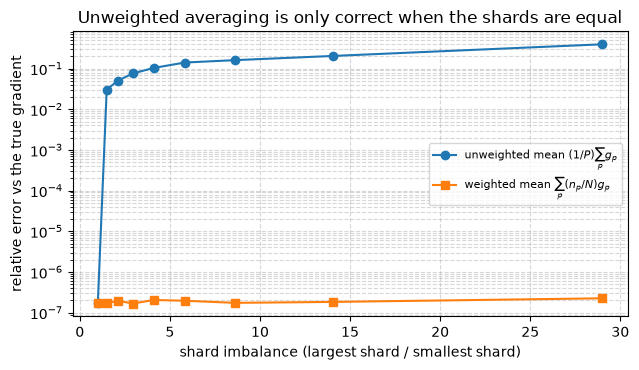

In [4]:
# --- Reference solution (instructor: blank this out for students) ---

def shard_grads(theta, X, Y, sizes):
    # per-shard LOCAL mean gradient -- exactly what client p computes and uploads
    out, start = [], 0
    for n_p in sizes:
        out.append(jax.grad(mean_loss)(theta, X[start:start + n_p], Y[start:start + n_p]))
        start += n_p
    return out


def agg_error(sizes):
    gs = shard_grads(theta, Xg, Yg, sizes)
    n = sum(sizes)
    unweighted = jax.tree.map(lambda *g: sum(g) / len(g), *gs)
    weighted = jax.tree.map(lambda *g: sum(gi * (s / n) for gi, s in zip(g, sizes)), *gs)
    denom = float(jnp.linalg.norm(flat(g_global)))
    return (float(jnp.linalg.norm(flat(unweighted) - flat(g_global))) / denom,
            float(jnp.linalg.norm(flat(weighted) - flat(g_global))) / denom)


sizes = [160, 64, 24, 8]
e_un, e_w = agg_error(sizes)
print(f"shard sizes {sizes}, total {sum(sizes)}")
print(f"   unweighted mean  (1/P) sum g_p   : relative error {e_un:.3e}   <- BIASED")
print(f"   weighted   mean  sum (n_p/N) g_p : relative error {e_w:.3e}   <- exact")
print(f"\n   the weighted aggregator is exact to float noise; the unweighted one is")
print(f"   wrong by {100 * e_un:.0f}% of the gradient's magnitude -- it over-weights the")
print(f"   8-example shard by {(sum(sizes) / len(sizes)) / 8:.0f}x relative to its true share.")

# sweep the imbalance: interpolate between balanced (64,64,64,64) and extreme (232,8,8,8)
balanced = np.array([64, 64, 64, 64])
extreme = np.array([232, 8, 8, 8])
alphas = np.linspace(0.0, 1.0, 9)
errs_un, errs_w, imbalance = [], [], []
for a in alphas:
    s = np.round((1 - a) * balanced + a * extreme).astype(int)
    s[0] += N - int(s.sum())                       # keep the total at exactly N
    eu, ew = agg_error([int(v) for v in s])
    errs_un.append(eu); errs_w.append(ew)
    imbalance.append(float(s.max() / s.min()))     # max/min shard size

plt.figure(figsize=(6.5, 3.8))
plt.semilogy(imbalance, errs_un, "o-", label="unweighted mean $(1/P)\\sum_p g_p$")
plt.semilogy(imbalance, np.maximum(errs_w, 1e-9), "s-", label="weighted mean $\\sum_p (n_p/N) g_p$")
plt.xlabel("shard imbalance (largest shard / smallest shard)")
plt.ylabel("relative error vs the true gradient")
plt.title("Unweighted averaging is only correct when the shards are equal")
plt.legend(fontsize=8)
plt.grid(True, ls="--", alpha=0.5, which="both")
plt.tight_layout()

print(f"\nimbalance 1x  -> unweighted error {errs_un[0]:.2e}  (equal shards: the two agree)")
print(f"imbalance {imbalance[-1]:.0f}x -> unweighted error {errs_un[-1]:.2e}")
print("\nRe-derived: FedAvg aggregates with weights n_k / n. That weight is not a")
print("heuristic and it is not fairness -- it is the ONLY aggregator that reproduces")
print("the gradient of the pooled loss when clients hold different amounts of data.")

## 2. Mesh and NamedSharding: choosing where data lives

JAX’s sharding API answers two questions:

1. How are the devices arranged?
   A Mesh organizes devices into a grid and gives each grid axis a name.
2. How is an array divided across the devices?
   A PartitionSpec says which array axes are split across which mesh axes.

NamedSharding(mesh, spec) combines these two pieces. It can be used with device_put and jit.

This week, the mesh has one axis named 'data'. In data parallelism, we split the batch across devices and copy everything else to every device.

Next week, we will add another mesh axis named 'model' and split model parameters across it. The same API still works.

mesh = Mesh(devices, ('data',))  # Devices arranged along the 'data' axis

> P('data')        # Split array axis 0 across devices

> P()              # Do not split the array; copy it to every device

> P(None, 'data')  # Keep axis 0 unchanged and split array axis 1

A PartitionSpec uses the position of each entry:

- The first entry describes array axis 0.
- The second entry describes array axis 1.
- None means that the axis is not split.
- Any array axis that is not mentioned is also not split.

In [4]:
P_DEV = 4
mesh = Mesh(np.array(jax.devices()[:P_DEV]), ("data",))
print("mesh:", mesh)
print("axis names:", mesh.axis_names, " shape:", mesh.shape)
print()

batch = jnp.arange(8 * 3, dtype=jnp.float32).reshape(8, 3)

sharded = jax.device_put(batch, NamedSharding(mesh, P("data", None)))   # split axis 0
replicated = jax.device_put(batch, NamedSharding(mesh, P()))            # every device: all

print("global shape (both):", sharded.shape, replicated.shape, " <- IDENTICAL. Sharding is")
print("                                              invisible to the program's logic.")
print()
print("sharded   -> per-device buffer shapes:", [s.data.shape for s in sharded.addressable_shards])
print("replicated-> per-device buffer shapes:", [s.data.shape for s in replicated.addressable_shards])
print()
print("device 0 actually holds, under P('data', None):")
print(np.asarray(sharded.addressable_shards[0].data))
print("device 3 actually holds:")
print(np.asarray(sharded.addressable_shards[3].data))

mesh: Mesh('data': 4, axis_types=(Auto,))
axis names: ('data',)  shape: OrderedDict([('data', 4)])

global shape (both): (8, 3) (8, 3)  <- IDENTICAL. Sharding is
                                              invisible to the program's logic.

sharded   -> per-device buffer shapes: [(2, 3), (2, 3), (2, 3), (2, 3)]
replicated-> per-device buffer shapes: [(8, 3), (8, 3), (8, 3), (8, 3)]

device 0 actually holds, under P('data', None):
[[0. 1. 2.]
 [3. 4. 5.]]
device 3 actually holds:
[[18. 19. 20.]
 [21. 22. 23.]]


In [5]:
print("P('data', None) -- the batch axis is split across 4 devices:")
jax.debug.visualize_array_sharding(sharded)

print("\nP() -- replicated: every device has a full copy:")
jax.debug.visualize_array_sharding(replicated)

print("\nP(None, 'data') -- the FEATURE axis is split instead (this is Week 6's move):")
feature_sharded = jax.device_put(jnp.zeros((8, 4)), NamedSharding(mesh, P(None, "data")))
jax.debug.visualize_array_sharding(feature_sharded)

P('data', None) -- the batch axis is split across 4 devices:


         
  CPU 0  
         
         
  CPU 1  
         
         
  CPU 2  
         
         
  CPU 3  
         


P() -- replicated: every device has a full copy:


           
           
           
           
           
CPU 0,1,2,3
           
           
           
           
           


P(None, 'data') -- the FEATURE axis is split instead (this is Week 6's move):


                                    
                                    
                                    
                                    
                                    
  CPU 0    CPU 1    CPU 2    CPU 3  
                                    
                                    
                                    
                                    
                                    

### What replication costs, and why we accept it

Data parallelism replicates the model on every device. That is an honest cost and it has a name: at $P$ devices you are storing $P$ copies of the parameters, $P$ copies of the optimizer state, and $P$ copies of the gradients. Adam's state alone is 2 extra copies of the parameters, so the replicated-per-device bill is roughly $4|\theta|$ before a single activation is allocated.

That is the whole reason Week 6 exists. Once the model no longer fits on one device,
replicating it $P$ times is not a memory *inefficiency* — it is a memory *impossibility*,
and you must shard the parameters themselves (ZeRO, tensor parallelism). Let us put the
numbers on the table now so that Week 6's motivation is a fact rather than a claim.


In [7]:
def replicated_bill(n_params, P_dev, optimizer="adam", bytes_per=4):
    per_copy = n_params * bytes_per
    n_copies = {"sgd": 1 + 1, "sgd+momentum": 1 + 1 + 1, "adam": 1 + 1 + 2}[optimizer]
    # params + gradients (+ optimizer state), PER DEVICE, and identical on every device
    return per_copy * n_copies, per_copy * n_copies * P_dev


print(f"{'model':>18}  {'params':>11}  {'per device':>12}  {'x8 devices':>12}  {'fits an 80GB A100?':>19}")
print("-" * 80)
for name, n in [("our Stage 1 ResNet", 9876), ("ResNet-50", 25.6e6), ("GPT-2 (1.5B)", 1.5e9),
                ("Llama-3 8B", 8.0e9), ("Llama-3 70B", 70e9)]:
    per, tot = replicated_bill(n, 8, "adam")
    fits = "yes" if per < 80e9 else "NO -- see Week 6"
    p_str = f"{n / 1e6:>9.2f}M" if n >= 1e6 else f"{n:>10,}"
    b_str = f"{per / 1e6:>9.1f} MB" if per < 1e9 else f"{per / 1e9:>9.1f} GB"
    t_str = f"{tot / 1e6:>9.1f} MB" if tot < 1e9 else f"{tot / 1e9:>9.1f} GB"
    print(f"{name:>18}  {p_str:>11}  {b_str:>12}  {t_str:>12}  {fits:>19}")

print("\n(params + grads + Adam's m,v = 4 copies of the parameters, at fp32.)")
print("Llama-3 8B's replicated state is 128 GB. An 80 GB A100 cannot hold it ONCE --")
print("and data parallelism asks all 8 of them to hold the SAME 128 GB each.")
print("\nData parallelism replicates the model and shards the data. That trade is free")
print("when the model is small and IMPOSSIBLE when it is not -- note that the failure")
print("is not slowness, it is that the program does not run at all. No amount of")
print("interconnect fixes it. Week 6 shards the model instead.")

             model       params    per device    x8 devices   fits an 80GB A100?
--------------------------------------------------------------------------------
our Stage 1 ResNet        9,876        0.2 MB        1.3 MB                  yes
         ResNet-50       25.60M      409.6 MB        3.3 GB                  yes
      GPT-2 (1.5B)     1500.00M       24.0 GB      192.0 GB                  yes
        Llama-3 8B     8000.00M      128.0 GB     1024.0 GB     NO -- see Week 6
       Llama-3 70B    70000.00M     1120.0 GB     8960.0 GB     NO -- see Week 6

(params + grads + Adam's m,v = 4 copies of the parameters, at fp32.)
Llama-3 8B's replicated state is 128 GB. An 80 GB A100 cannot hold it ONCE --
and data parallelism asks all 8 of them to hold the SAME 128 GB each.

Data parallelism replicates the model and shards the data. That trade is free
when the model is small and IMPOSSIBLE when it is not -- note that the failure
is not slowness, it is that the program does not run at a

> **Observe:** a sharded array and a replicated array have the **same global shape**. The
> sharding lives in `x.sharding`, not in `x.shape`, and your program is written against the
> global shape as if one enormous device held everything. This is the central design
> decision of JAX's parallelism story and it is why Stage 2 needs no rewrite of Stage 1:
> you annotate *placement*, the compiler emits the *communication*. The next section makes
> that literal — we will find the AllReduce that we never wrote.


---

## 3. `jit` + shardings = data parallelism you did not write

Here is the part that looks like a magic trick and is not. Give `jax.jit` a function whose
inputs are sharded, and XLA's **GSPMD** partitioner propagates the shardings through every
operation in the program, works out where a partitioned intermediate has to be reconciled,
and **inserts the collectives itself**.

For a data-parallel training step the propagation goes:

```
   x  sharded on 'data'   ->  activations sharded on 'data'   (the batch axis just flows)
   θ  replicated          ->  per-example grads sharded on 'data'
   loss = mean over batch  ->  a reduction ACROSS the shard boundary
                                 -> XLA inserts an ALL-REDUCE here
   dθ replicated          ->  every device gets the identical update
```

You do not call `psum`. You do not restructure the loop. You say where the data is, and
the compiler discovers that averaging a sharded quantity requires the devices to talk.

We bring the Stage 1 codebase over **unchanged** — the same Equinox ResNet, the same four
separated states — and shard its input. The claim to check is that the answer is identical
to the single-device answer.


In [7]:
# ---- The Stage 1 codebase, verbatim from Weeks 3-4 ----
class ResBlock(eqx.Module):
    conv1: eqx.nn.Conv2d
    bn1: eqx.nn.BatchNorm
    conv2: eqx.nn.Conv2d
    bn2: eqx.nn.BatchNorm

    def __init__(self, channels, key, bn_momentum=0.9):
        k1, k2 = jax.random.split(key)
        self.conv1 = eqx.nn.Conv2d(channels, channels, 3, padding=1, use_bias=False, key=k1)
        self.bn1 = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)
        self.conv2 = eqx.nn.Conv2d(channels, channels, 3, padding=1, use_bias=False, key=k2)
        self.bn2 = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)

    def __call__(self, x, state):
        h, state = self.bn1(self.conv1(x), state)
        h = jax.nn.relu(h)
        h, state = self.bn2(self.conv2(h), state)
        return jax.nn.relu(x + h), state


class ResNet(eqx.Module):
    stem: eqx.nn.Conv2d
    stem_bn: eqx.nn.BatchNorm
    blocks: list
    head: eqx.nn.Linear

    def __init__(self, key, channels=16, n_blocks=2, n_classes=4, bn_momentum=0.9):
        ks = jax.random.split(key, n_blocks + 2)
        self.stem = eqx.nn.Conv2d(3, channels, 3, stride=2, padding=1, use_bias=False, key=ks[0])
        self.stem_bn = eqx.nn.BatchNorm(channels, axis_name="batch", mode="batch", momentum=bn_momentum)
        self.blocks = [ResBlock(channels, ks[i + 1], bn_momentum) for i in range(n_blocks)]
        self.head = eqx.nn.Linear(channels, n_classes, key=ks[-1])

    def __call__(self, x, state):
        x, state = self.stem_bn(self.stem(x), state)
        x = jax.nn.relu(x)
        for block in self.blocks:
            x, state = block(x, state)
        x = jnp.mean(x, axis=(1, 2))
        return self.head(x), state


def batched_forward(model, state, x):
    return eqx.filter_vmap(lambda m, s, xi: m(xi, s), in_axes=(None, None, 0),
                           out_axes=(0, None), axis_name="batch")(model, state, x)


def loss_fn(model, state, x, y):
    logits, state = batched_forward(model, state, x)
    return optax.softmax_cross_entropy_with_integer_labels(logits, y).mean(), state


# ---- Week 3's synthetic CIFAR-shaped data (the harness has no network) ----
N_CLASSES, IMG = 4, 32

def make_templates(key, n_classes=N_CLASSES, size=IMG):
    lo = jax.random.normal(key, (n_classes, 3, 8, 8))
    return jax.image.resize(lo, (n_classes, 3, size, size), method="linear")

def make_data(n, key, templates, noise=1.0):
    k_lab, k_noise = jax.random.split(key)
    labels = jax.random.randint(k_lab, (n,), 0, templates.shape[0])
    noise_arr = jax.random.normal(k_noise, (n,) + templates.shape[1:]) * noise
    return templates[labels] + noise_arr, labels

TEMPLATES = make_templates(jax.random.key(7))
X_tr, Y_tr = make_data(2048, jax.random.key(1), TEMPLATES)

# ---- the four states, still separated ----
model0, bn0 = eqx.nn.make_with_state(ResNet)(jax.random.key(1))     # 1. params  2. batch stats
params0, static0 = eqx.partition(model0, eqx.is_inexact_array)
optimizer = optax.sgd(1e-2, momentum=0.9)
opt0 = optimizer.init(params0)                                      # 3. optimizer state
train_key = jax.random.key(123)                                     # 4. PRNG

n_params = flat(params0).size
print(f"model : {n_params:,} parameters ({flat(params0).nbytes / 1024:.1f} KiB at fp32)")
print(f"data  : {X_tr.shape} synthetic CIFAR-shaped (real lab: CIFAR-10 via Grain on the GPU node)")
print(f"states: params | batch stats | opt state | PRNG   <- still four, still separate")

model : 9,876 parameters (38.6 KiB at fp32)
data  : (2048, 3, 32, 32) synthetic CIFAR-shaped (real lab: CIFAR-10 via Grain on the GPU node)
states: params | batch stats | opt state | PRNG   <- still four, still separate


In [8]:
def train_step(params, bn_state, opt_state, x, y):
    def _loss(p, s):
        return loss_fn(eqx.combine(p, static0), s, x, y)
    (loss, bn_state), grads = jax.value_and_grad(_loss, has_aux=True)(params, bn_state)
    updates, opt_state = optimizer.update(grads, opt_state, params)
    return eqx.apply_updates(params, updates), bn_state, opt_state, loss


GLOBAL_BATCH = 256
xb, yb = X_tr[:GLOBAL_BATCH], Y_tr[:GLOBAL_BATCH]

# --- 1 device: the Stage 1 baseline
step_1dev = jax.jit(train_step)
p1, b1, o1, l1 = jax.block_until_ready(step_1dev(params0, bn0, opt0, xb, yb))

# --- 4 devices: the SAME function. Only the input placement changed.
data_sh = NamedSharding(mesh, P("data"))       # batch axis -> 'data'   (SHARDED)
rep_sh = NamedSharding(mesh, P())              # everything else        (REPLICATED)

xb_s, yb_s = jax.device_put(xb, data_sh), jax.device_put(yb, data_sh)
p_s = jax.device_put(params0, rep_sh)
b_s = jax.device_put(bn0, rep_sh)
o_s = jax.device_put(opt0, rep_sh)

step_4dev = jax.jit(train_step, in_shardings=(rep_sh, rep_sh, rep_sh, data_sh, data_sh),
                    out_shardings=(rep_sh, rep_sh, rep_sh, rep_sh))
p4, b4, o4, l4 = jax.block_until_ready(step_4dev(p_s, b_s, o_s, xb_s, yb_s))

print(f"global batch {GLOBAL_BATCH}  ->  {GLOBAL_BATCH // P_DEV} examples per device on {P_DEV} devices")
print()
print(f"loss, 1 device  : {float(l1):.8f}")
print(f"loss, 4 devices : {float(l4):.8f}")
print(f"|difference|    : {abs(float(l1) - float(l4)):.2e}")
print()
d = float(jnp.max(jnp.abs(flat(p1) - flat(p4))))
print(f"max |param_1dev - param_4dev| after one step: {d:.2e}   "
      f"(relative {d / float(jnp.max(jnp.abs(flat(p1)))):.1e})")
print("\nThe SAME train_step function. Not one line of the model, the loss, or the")
print("optimizer changed. We annotated placement; the compiler did the rest.")

global batch 256  ->  64 examples per device on 4 devices

loss, 1 device  : 1.42512906
loss, 4 devices : 1.42512918
|difference|    : 1.19e-07

max |param_1dev - param_4dev| after one step: 7.45e-09   (relative 7.4e-09)

The SAME train_step function. Not one line of the model, the loss, or the
optimizer changed. We annotated placement; the compiler did the rest.


### Find the AllReduce

"The compiler inserted a collective" is a claim, and this course does not accept claims. The compiled HLO is right there — go and look at it. Count the `all-reduce` operations in the 1-device program and in the 4-device program.


In [9]:
import re

def collective_report(compiled, label, quiet=False):
    txt = compiled.as_text()
    ops = {}
    for line in txt.split(chr(10)):
        m = re.search(r"=\s*\S+\s+(all-reduce|all-gather|reduce-scatter|collective-permute|all-to-all)"
                      r"(?:-start|-done)?\(", line)
        if m:
            ops[m.group(1)] = ops.get(m.group(1), 0) + 1
    total = sum(ops.values())
    if not quiet:
        print(f"{label:>28}  collectives: {total:>3}   {ops if ops else '{}'}")
    return txt, ops


c1 = step_1dev.lower(params0, bn0, opt0, xb, yb).compile()
c4 = step_4dev.lower(p_s, b_s, o_s, xb_s, yb_s).compile()

print(f"{'program':>28}  {'what XLA emitted'}")
print("-" * 78)
txt1, ops1 = collective_report(c1, "1 device (Stage 1)")
txt4, ops4 = collective_report(c4, "4 devices, data-sharded")

print()
first = [l.strip() for l in txt4.split(chr(10)) if re.search(r"=\s*\S+\s+all-reduce\(", l)]
print("the first all-reduce in the 4-device program:")
print("   ", first[0][:150])
print()
print("Read the operand shape: that is a gradient tensor, being summed across the")
print("mesh axis. We never wrote a collective. GSPMD saw a reduction over a sharded")
print("axis and emitted the communication that makes it correct.")

                     program  what XLA emitted
------------------------------------------------------------------------------
          1 device (Stage 1)  collectives:   0   {}
     4 devices, data-sharded  collectives:  15   {'all-reduce': 15}

the first all-reduce in the 4-device program:
    %all-reduce = f32[16]{0} all-reduce(%wrapped_reduce), channel_id=1, replica_groups=mesh['axis_0'=4,'axis_1'=1] {'axis_0'}, use_global_device_ids=true,

Read the operand shape: that is a gradient tensor, being summed across the
mesh axis. We never wrote a collective. GSPMD saw a reduction over a sharded
axis and emitted the communication that makes it correct.


In [10]:
# The invariant data parallelism lives or dies by: after the step, is every replica
# still holding EXACTLY the same parameters? If they ever diverge, you no longer have
# one model being trained -- you have P models, and no error will tell you.
def replicas_identical(tree):
    worst = 0.0
    for leaf in jax.tree.leaves(tree):
        shards = [np.asarray(s.data) for s in leaf.addressable_shards]
        worst = max(worst, max(float(np.max(np.abs(s - shards[0]))) for s in shards))
    return worst


print("parameters after one 4-device step:")
print(f"   sharding      : {p4.stem.weight.sharding.spec}   <- P() = replicated")
print(f"   copies held   : {len(p4.stem.weight.addressable_shards)} (one per device)")
print(f"   max disagreement between replicas: {replicas_identical(p4):.3e}   <- BIT-IDENTICAL")
print()
print("Not 'close'. Identical -- every device ran the same all-reduce and got the same")
print("bits, so it applied the same update to the same starting point. That invariant is")
print("what lets you checkpoint from device 0 and ignore the rest, and it is the FIRST")
print("thing Week 7 gives up: after tau local steps the replicas genuinely differ, and")
print("'which model is THE model?' becomes a real question with a real answer (the average).")

parameters after one 4-device step:
   sharding      : P()   <- P() = replicated
   copies held   : 4 (one per device)
   max disagreement between replicas: 0.000e+00   <- BIT-IDENTICAL

Not 'close'. Identical -- every device ran the same all-reduce and got the same
bits, so it applied the same update to the same starting point. That invariant is
what lets you checkpoint from device 0 and ignore the rest, and it is the FIRST
thing Week 7 gives up: after tau local steps the replicas genuinely differ, and
'which model is THE model?' becomes a real question with a real answer (the average).


### Why are there so many AllReduces? A preview of Week 11

There is more than one AllReduce because two parts of each training step must combine information from all devices:

1. Gradients. Each parameter tensor needs a reduction. XLA usually combines many small reductions into a few large ones because many small AllReduces are slow.
2. BatchNorm statistics. BatchNorm calculates the mean and variance of a batch. Because the batch is split across devices, JAX must combine the local statistics to get global statistics. This requires another AllReduce for every BatchNorm layer at every step.

With jit and GSPMD, JAX automatically computes global BatchNorm statistics. Therefore, training on four devices behaves like single-device training with the full batch. This is why the losses matched to about 10⁻⁷. However, global statistics require extra communication.

Another option is to calculate BatchNorm statistics separately on each device. This is called Ghost BatchNorm. It uses less communication, and its additional noise can sometimes improve regularization.

Federated learning is different. Clients cannot share BatchNorm statistics at every step because they are trained separately. Their statistics remain local. When clients have different data distributions, their statistics can also be very different.

FedBN, which we study in Week 11, uses this idea: it keeps BatchNorm parameters on each client instead of averaging them. The number of collectives in this example is our first hint of that problem.

> **Observe:** the single-device program contains **zero** collectives and the
> data-sharded program contains many — same source code, same math, same answer to 1e-7.
> The AllReduce is not something you add to your model; it is what the compiler must do to
> keep your model's meaning intact once its inputs are cut in pieces.
>
> This is also the moment to notice what you have **lost**: with GSPMD you no longer know
> what is being communicated unless you read the HLO. Convenient is not the same as
> transparent, and in an HPML course transparency wins ties. That is what `shard_map` is
> for.


### 🔬 Exercise 2

**Exercise:** the batch does not always divide by $P$.

Try to `device_put` a batch of **250** examples onto a 4-device mesh with `P('data')` and
read the error. Then fix it two ways, reusing Week 4's Exercise 4 answer:
(a) drop the remainder so the batch divides, (b) **pad and mask** so the global shape is
always divisible.

Compare both against the true loss on the 250 real examples, and say which fix you would
use in Week 9 — where every client's dataset size is a different number nobody chose.

One of the two fixes will turn out **not** to be exact, for a reason that is not about
padding at all. Find it before you read the last print statement.


In [12]:
# --- Reference solution (instructor: blank this out for students) ---

RAGGED = 250
x_ragged, y_ragged = X_tr[:RAGGED], Y_tr[:RAGGED]

# (0) the error
try:
    jax.device_put(x_ragged, data_sh)
    print("no error?!")
except ValueError as e:
    print(f"device_put({RAGGED} examples) on a {P_DEV}-device mesh ->", type(e).__name__)
    print("   ", str(e).split(chr(10))[0][:120])
    print(f"    ({RAGGED} = {P_DEV} x {RAGGED // P_DEV} + {RAGGED % P_DEV}: the mesh cannot split it evenly)")

# (a) drop the remainder
keep = (RAGGED // P_DEV) * P_DEV
x_drop = jax.device_put(x_ragged[:keep], data_sh)
loss_drop, _ = jax.jit(lambda p, s, x, y: loss_fn(eqx.combine(p, static0), s, x, y),
                       in_shardings=(rep_sh, rep_sh, data_sh, data_sh))(
    p_s, b_s, x_drop, jax.device_put(y_ragged[:keep], data_sh))
print(f"\n(a) drop  : keep {keep}, discard {RAGGED - keep} examples "
      f"({100 * (RAGGED - keep) / RAGGED:.1f}%).  loss = {float(loss_drop):.6f}")

# (b) pad to a multiple of P, and mask the padding out of the mean
def masked_loss(params, state, x, y, m):
    logits, state = batched_forward(eqx.combine(params, static0), state, x)
    per = optax.softmax_cross_entropy_with_integer_labels(logits, y)
    return jnp.sum(per * m) / jnp.sum(m), state          # <- weight by the mask, not by len(x)

n_pad = (-RAGGED) % P_DEV
x_pad = jnp.concatenate([x_ragged, jnp.zeros((n_pad,) + x_ragged.shape[1:])])
y_pad = jnp.concatenate([y_ragged, jnp.zeros(n_pad, dtype=y_ragged.dtype)])
m_pad = jnp.concatenate([jnp.ones(RAGGED), jnp.zeros(n_pad)])

loss_pad, _ = jax.jit(masked_loss, in_shardings=(rep_sh, rep_sh, data_sh, data_sh, data_sh))(
    p_s, b_s, jax.device_put(x_pad, data_sh), jax.device_put(y_pad, data_sh),
    jax.device_put(m_pad, data_sh))

# ground truth: the same 250 examples, one device, no padding
loss_true, _ = jax.jit(lambda p, s, x, y: loss_fn(eqx.combine(p, static0), s, x, y))(
    params0, bn0, x_ragged, y_ragged)

print(f"(b) pad+mask: {RAGGED} + {n_pad} padding = {RAGGED + n_pad} "
      f"({(RAGGED + n_pad) // P_DEV} per device).  loss = {float(loss_pad):.6f}")
print(f"    ground truth on the real {RAGGED} examples (1 device): {float(loss_true):.6f}")
print(f"    |pad+mask - truth| = {abs(float(loss_pad) - float(loss_true)):.2e}  <- close, NOT exact")
print(f"    |drop     - truth| = {abs(float(loss_drop) - float(loss_true)):.2e}  <- "
      f"{abs(float(loss_drop) - float(loss_true)) / abs(float(loss_pad) - float(loss_true)):.0f}x worse: "
      f"{RAGGED - keep} examples never voted")

print("\nWhy isn't pad+mask EXACT? The mask fixes the LOSS. It does not fix the MODEL.")
print("BatchNorm in mode='batch' computes its mean and variance over the whole batch --")
print(f"including our {n_pad} rows of zeros. The padding never contributes to the loss and")
print("still perturbs every normalized activation, because BatchNorm is the one layer")
print("whose output for example i DEPENDS ON example j. Mask the loss and the padding")
print("leaks in through the statistics anyway. (Fixes: masked BN statistics, or pad with")
print("real examples instead of zeros. Neither is free.)")

print("\nWeek 9 answer: pad + mask -- it is 5x more accurate here and, more importantly,")
print("it keeps ONE shape, so one compile (Week 4's lesson) instead of one per client.")
print("Note WHY the mask must weight the mean: sum(per*m)/sum(m) is a WEIGHTED average,")
print("the same n_k/N weighting as Exercise 1. Ragged data and weighted aggregation are")
print("the same problem twice.")
print("\nAnd file the BatchNorm finding away. A layer that couples examples inside a")
print("batch is a layer that breaks every time the batch changes meaning -- padded")
print("here, per-client and non-IID in Week 11. That is why FedBN exists.")

device_put(250 examples) on a 4-device mesh -> IndivisibleError
    Sharding NamedSharding(mesh=Mesh('data': 4, axis_types=(Auto,)), spec=P('data',), memory_kind=device) implies that array
    (250 = 4 x 62 + 2: the mesh cannot split it evenly)



(a) drop  : keep 248, discard 2 examples (0.8%).  loss = 1.424383


(b) pad+mask: 250 + 2 padding = 252 (63 per device).  loss = 1.423354
    ground truth on the real 250 examples (1 device): 1.423100
    |pad+mask - truth| = 2.54e-04  <- close, NOT exact
    |drop     - truth| = 1.28e-03  <- 5x worse: 2 examples never voted

Why isn't pad+mask EXACT? The mask fixes the LOSS. It does not fix the MODEL.
BatchNorm in mode='batch' computes its mean and variance over the whole batch --
including our 2 rows of zeros. The padding never contributes to the loss and
still perturbs every normalized activation, because BatchNorm is the one layer
whose output for example i DEPENDS ON example j. Mask the loss and the padding
leaks in through the statistics anyway. (Fixes: masked BN statistics, or pad with
real examples instead of zeros. Neither is free.)

Week 9 answer: pad + mask -- it is 5x more accurate here and, more importantly,
it keeps ONE shape, so one compile (Week 4's lesson) instead of one per client.
Note WHY the mask must weight the mean: sum(per*m)/su

---

## 4. `shard_map`: writing the per-device program yourself

`jit`+GSPMD is *global-view*: you write one program over global shapes and the compiler
decides what is communicated. `shard_map` is *per-device view*: your function receives the
**local shard** and you call the collectives **by hand**. Nothing is inferred and nothing
is inserted.

| | `jit` + shardings (GSPMD) | `shard_map` |
|---|---|---|
| what your function sees | **global** shapes | the **local shard**'s shape |
| who inserts collectives | the compiler | **you** |
| when it is wrong | you find out by reading the HLO | you find out from the type error |
| good for | data parallelism, most of the time | anything where you must *know* the traffic |
| the Week 5 use | the training step | Ring AllReduce, communication accounting |
| the Week 6 use | — | tensor-parallel matmuls |
| the Week 7 use | — | Local SGD: $\tau$ steps, *then* one collective |

The contract is three arguments: `mesh` (which devices), `in_specs` (how each argument is
already split), `out_specs` (how the return value should be interpreted). Inside the body,
shapes are **per-device**, and `jax.lax.psum(x, 'data')` is a real message-passing
operation across the named mesh axis.

Here is data parallelism written out longhand — which is to say, here is the algorithm from
Section 1, typed in.


In [13]:
# per-device batch and a fresh copy of the MLP from Section 1
theta_rep = jax.device_put(theta, rep_sh)
Xg_s = jax.device_put(Xg, data_sh)
Yg_s = jax.device_put(Yg, data_sh)


def dp_grad_manual(params, x, y):
    # INSIDE shard_map: x is THIS DEVICE's shard, shape (N/P, D). Not (N, D).
    print(f"   [trace] this device sees x of shape {x.shape} out of a global {Xg.shape}")
    # average the LOSS across devices, then differentiate. (Why this order and not the
    # other one is the whole next cell -- it is not a stylistic choice.)
    return jax.grad(lambda p: jax.lax.pmean(mean_loss(p, x, y), "data"))(params)


manual = jax.jit(jax.shard_map(dp_grad_manual, mesh=mesh,
                               in_specs=(P(), P("data"), P("data")),
                               out_specs=P()))
g_manual = manual(theta_rep, Xg_s, Yg_s)

err = float(jnp.max(jnp.abs(flat(g_manual) - flat(g_global))))
print(f"\nmax |shard_map gradient - single-device gradient| = {err:.3e}")
print("\nThat is Section 1's algorithm, typed in: replicated params, a local loss on the")
print("local shard, one all-reduce. It is what GSPMD emitted for us in Section 3.")

   [trace] this device sees x of shape (64, 32) out of a global (256, 32)



max |shard_map gradient - single-device gradient| = 4.768e-07

That is Section 1's algorithm, typed in: replicated params, a local loss on the
local shard, one all-reduce. It is what GSPMD emitted for us in Section 3.


### The collective you did **not** write, and the 4× bug it causes

Now the subtle part, and it is the best reason to spend a week on `shard_map` at all.

The obvious way to write the cell above is `pmean(grad(loss))` — compute the local
gradient, then average it. It reads exactly like Section 1's derivation. **It is wrong by a
factor of $P$**, and nothing raises.

Here is why, and it is pure Week 2. Reverse-mode AD works by **transposing** the forward
program, and the transpose of *broadcast* is *sum*. Inside `shard_map`, the parameters are
declared **replicated** (`in_specs=P()`) — and "replicated" is, formally, a broadcast of one
value to $P$ devices. So when you differentiate with respect to it, JAX must transpose that
broadcast, and it inserts a **`psum` on the cotangent automatically**. The gradient handed
back by `jax.grad` inside `shard_map` has *already been all-reduced*, as a **sum**, whether
or not you asked.

So `pmean(grad(...))` reduces a quantity that was already reduced. Watch the factors.


In [14]:
def variants(label, f):
    g = jax.jit(jax.shard_map(f, mesh=mesh, in_specs=(P(), P("data"), P("data")),
                              out_specs=P()))(theta_rep, Xg_s, Yg_s)
    ratio = float(jnp.linalg.norm(flat(g)) / jnp.linalg.norm(flat(g_global)))
    ok = "correct" if abs(ratio - 1) < 1e-3 else f"WRONG by {ratio:.0f}x"
    print(f"{label:>34}  ||g|| / ||g_true|| = {ratio:>7.3f}   {ok}")


print(f"P = {P_DEV} devices, params replicated, data sharded\n")
variants("grad(loss)          no collective", lambda p, x, y: jax.grad(mean_loss)(p, x, y))
variants("pmean(grad(loss))   'the obvious'", lambda p, x, y: jax.lax.pmean(jax.grad(mean_loss)(p, x, y), "data"))
variants("psum(grad(loss))", lambda p, x, y: jax.lax.psum(jax.grad(mean_loss)(p, x, y), "data"))
print()
variants("grad(pmean(loss))   THE IDIOM", lambda p, x, y: jax.grad(lambda q: jax.lax.pmean(mean_loss(q, x, y), "data"))(p))
variants("grad(loss) / P      equivalent", lambda p, x, y: jax.tree.map(lambda g: g / P_DEV, jax.grad(mean_loss)(p, x, y)))

print()
print(f"Read the first line again: writing NO collective at all already gives a gradient")
print(f"that is P = {P_DEV}x the mean -- i.e. the SUM of the per-device gradients. AD inserted")
print("the psum for us, because the transpose of 'replicate' is 'sum'.")
print()
print("So 'the obvious' pmean(grad(...)) is psum(already-summed)/P and comes out P x too")
print(f"large. That is Section 1's psum-vs-pmean bug arriving through a door you cannot")
print(f"see -- an unannounced {P_DEV}x learning rate, on {P_DEV} devices, silently.")
print()
print("The idiom to memorize: differentiate the AVERAGED LOSS -- grad(pmean(loss)).")
print("Let AD place the collective; it knows where it belongs. (Equivalently: divide")
print("the auto-summed gradient by P yourself -- last line. Same program.)")

P = 4 devices, params replicated, data sharded

 grad(loss)          no collective  ||g|| / ||g_true|| =   4.000   WRONG by 4x
 pmean(grad(loss))   'the obvious'  ||g|| / ||g_true|| =   4.000   WRONG by 4x


                  psum(grad(loss))  ||g|| / ||g_true|| =  16.000   WRONG by 16x

     grad(pmean(loss))   THE IDIOM  ||g|| / ||g_true|| =   1.000   correct
    grad(loss) / P      equivalent  ||g|| / ||g_true|| =   1.000   correct

Read the first line again: writing NO collective at all already gives a gradient
that is P = 4x the mean -- i.e. the SUM of the per-device gradients. AD inserted
the psum for us, because the transpose of 'replicate' is 'sum'.

So 'the obvious' pmean(grad(...)) is psum(already-summed)/P and comes out P x too
large. That is Section 1's psum-vs-pmean bug arriving through a door you cannot
see -- an unannounced 4x learning rate, on 4 devices, silently.

The idiom to memorize: differentiate the AVERAGED LOSS -- grad(pmean(loss)).
Let AD place the collective; it knows where it belongs. (Equivalently: divide
the auto-summed gradient by P yourself -- last line. Same program.)


### When the type system *does* catch you

`out_specs=P()` is a **promise** that the returned value is identical on every device. The
gradient above slipped through because AD had *genuinely* made it replicated — just with the
wrong scale factor, and a type system checks types, not arithmetic. Write a non-AD function
that returns something genuinely per-device, though, and the promise is checked and refused
at trace time.


In [15]:
def local_sum_no_collective(x):
    return jnp.sum(x, axis=0)          # THIS DEVICE's partial sum. Not replicated.


try:
    jax.shard_map(local_sum_no_collective, mesh=mesh, in_specs=P("data", None),
                  out_specs=P(None))(sharded)
    print("no error?!")
except ValueError as e:
    lines = [l for l in str(e).split(chr(10)) if l.strip()]
    print("out_specs=P(None) with no collective ->", type(e).__name__)
    for l in lines:
        if "replicat" in l:
            print("   ", l.strip()[:105])
            break

print("\nFixed by saying what you meant:")
ok = jax.shard_map(lambda x: jax.lax.psum(jnp.sum(x, axis=0), "data"), mesh=mesh,
                   in_specs=P("data", None), out_specs=P(None))(sharded)
print("   psum(local sum) =", np.asarray(ok), " | true column sums =", np.asarray(jnp.sum(batch, axis=0)))
print("\nThe lesson is the pair, not either half: the type system catches a MISSING")
print("collective, and it cannot catch a WRONGLY SCALED one. Types are not arithmetic.")
print("Check your gradient against a single-device reference. Every time. It is one line.")

out_specs=P(None) with no collective -> ValueError
    shard_map applied to the function '_rem_singleton' was given out_specs which require replication which ca

Fixed by saying what you meant:


   psum(local sum) = [ 84.  92. 100.]  | true column sums = [ 84.  92. 100.]

The lesson is the pair, not either half: the type system catches a MISSING
collective, and it cannot catch a WRONGLY SCALED one. Types are not arithmetic.
Check your gradient against a single-device reference. Every time. It is one line.


### The collectives, and what each one costs

`psum` is one of a small family, and the whole of Part II is built from it. Every one is a
`jax.lax` function callable inside `shard_map` (or under `pmap`), and every one takes the
**axis name** — which must match a name in your mesh, because that is how JAX knows *which*
devices are talking.

| collective | JAX | each device ends up with | bytes/worker (ring) | where you meet it |
|---|---|---|---|---|
| **all-reduce** | `psum` / `pmean` | the fully reduced array | $\frac{2(P-1)}{P}S$ | data parallelism (today), FedAvg |
| **reduce-scatter** | `psum_scatter` | its $1/P$ slice, reduced | $\frac{P-1}{P}S$ | ZeRO, half of the ring (Wk 6) |
| **all-gather** | `all_gather` | everyone's shards, concatenated | $\frac{P-1}{P}S$ | ZeRO, the other half (Wk 6) |
| **permute** | `ppermute` | one neighbour's array | $S$ (what you sent) | building rings by hand (§5) |
| **all-to-all** | `all_to_all` | a transposed sharding | $\frac{P-1}{P}S$ | MoE routing, resharding |
| **axis index** | `axis_index` | "who am I?" — no communication | 0 | indexing into a ring |

Two identities worth carrying: **all-reduce = reduce-scatter + all-gather** (Exercise 3
proves it, and it is why the ring's cost is exactly twice the one-way cost), and ZeRO
(Week 6) is *nothing but* noticing that a data-parallel step already does both halves and
that you need not materialize the middle.


In [16]:
x_col = jnp.arange(P_DEV * 4, dtype=jnp.float32).reshape(P_DEV, 4)      # device i -> row i
x_col_s = jax.device_put(x_col, NamedSharding(mesh, P("data", None)))
print("input: device i holds row i =")
print(np.asarray(x_col), "\n")


def show(label, f, out_spec, **kw):
    r = jax.shard_map(f, mesh=mesh, in_specs=P("data", None), out_specs=out_spec, **kw)(x_col_s)
    per_dev = [np.asarray(s.data).ravel() for s in r.addressable_shards]
    print(f"{label:>32}  device0 -> {str(per_dev[0]):<28}  device3 -> {per_dev[-1]}")


show("psum      (all-reduce, sum)", lambda a: jax.lax.psum(a, "data"), P(None, None))
show("pmean     (all-reduce, mean)", lambda a: jax.lax.pmean(a, "data"), P(None, None))
show("psum_scatter (reduce-scatter)",
     lambda a: jax.lax.psum_scatter(a[0], "data", tiled=True)[None, :], P("data", None))
show("all_gather", lambda a: jax.lax.all_gather(a, "data", axis=0, tiled=True),
     P(None, None), check_vma=False)
show("ppermute  (i -> i+1)",
     lambda a: jax.lax.ppermute(a, "data", [(i, (i + 1) % P_DEV) for i in range(P_DEV)]),
     P("data", None))
show("axis_index (no communication)",
     lambda a: jnp.full((1, 1), jax.lax.axis_index("data")), P("data", None))

print("\npsum_scatter: device 0 got the reduced values of COLUMN 0 only -- it holds 1/P")
print("of the answer. all_gather: everyone got all 16 values. Add the two and you have")
print("psum, which is the identity Exercise 3 makes you prove.")

input: device i holds row i =
[[ 0.  1.  2.  3.]
 [ 4.  5.  6.  7.]
 [ 8.  9. 10. 11.]
 [12. 13. 14. 15.]] 



     psum      (all-reduce, sum)  device0 -> [24. 28. 32. 36.]             device3 -> [24. 28. 32. 36.]
    pmean     (all-reduce, mean)  device0 -> [6. 7. 8. 9.]                 device3 -> [6. 7. 8. 9.]


   psum_scatter (reduce-scatter)  device0 -> [24.]                         device3 -> [36.]


                      all_gather  device0 -> [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15.]  device3 -> [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15.]
            ppermute  (i -> i+1)  device0 -> [12. 13. 14. 15.]             device3 -> [ 8.  9. 10. 11.]
   axis_index (no communication)  device0 -> [0]                           device3 -> [3]

psum_scatter: device 0 got the reduced values of COLUMN 0 only -- it holds 1/P
of the answer. all_gather: everyone got all 16 values. Add the two and you have
psum, which is the identity Exercise 3 makes you prove.


### Local vs global: the distinction `shard_map` forces you to see

Inside `shard_map`, **every reduction you write is local unless you say otherwise**.
`jnp.mean(x)` is the mean of *this device's* shard. `jax.lax.pmean(jnp.mean(x), 'data')` is
the mean of the whole batch (when the shards are equal — Exercise 1's caveat, again).

This is not a wart. It is the *entire* mental model of federated learning, arriving four
weeks early: a client can compute anything it likes about its own data for free, and
anything about anyone else's data only by paying for a round of communication.


In [17]:
def local_vs_global(x):
    local = jnp.mean(x)
    glob = jax.lax.pmean(local, "data")        # equal shards -> pmean of means = global mean
    return jnp.array([local]), jnp.array([glob])


loc, glo = jax.shard_map(local_vs_global, mesh=mesh, in_specs=P("data", None),
                         out_specs=(P("data"), P("data")))(sharded)

print("array:", np.asarray(batch).ravel()[:8], "...")
print()
print(f"{'device':>8}  {'jnp.mean(x)  (LOCAL)':>22}  {'pmean(..., data)  (GLOBAL)':>28}")
print("-" * 62)
for i in range(P_DEV):
    print(f"{i:>8}  {float(loc[i]):>22.4f}  {float(glo[i]):>28.4f}")
print(f"\ntrue global mean: {float(jnp.mean(batch)):.4f}")
print("\nEvery device computed a DIFFERENT local mean and the SAME global mean.")
print("The gap between those two columns is measured in bytes on the wire.")

array: [0. 1. 2. 3. 4. 5. 6. 7.] ...

  device    jnp.mean(x)  (LOCAL)    pmean(..., data)  (GLOBAL)
--------------------------------------------------------------
       0                  2.5000                       11.5000
       1                  8.5000                       11.5000
       2                 14.5000                       11.5000
       3                 20.5000                       11.5000

true global mean: 11.5000

Every device computed a DIFFERENT local mean and the SAME global mean.
The gap between those two columns is measured in bytes on the wire.


> **Observe:** `shard_map` costs you the illusion of a single big device and pays you back
> in **legibility**: every byte that crosses the interconnect corresponds to a collective
> you typed. For a data-parallel training step you should generally let `jit` do it — GSPMD
> fuses the gradient reductions better than you will. Reach for `shard_map` when the
> communication *is* the thing you are studying, which is this week's Section 5, Week 6's
> tensor parallelism, and Week 7's Local SGD.
>
> But notice what the $P\times$ bug just taught us, because it is bigger than a JAX
> quirk. "Every byte is one you typed" turned out to be **false** in the one place it
> mattered: `grad` inserted a `psum` we never wrote, correctly, following Week 2's transpose
> rule — and a plausible reading of Section 1's own derivation then produced a gradient
> $P\times$ too large with no error. `shard_map` is *more* explicit than GSPMD, not
> *fully* explicit, and "more explicit" is not a synonym for "safe".
>
> The defence is not vigilance, it is the one-line check we ran: **compare against a
> single-device reference**. It caught a 4× error instantly and it costs nothing. Everything
> from here to Week 13 is distributed, and every one of those weeks has a version of this
> bug in it.
>
> **A version note.** As of jax 0.10.2, calling a `vmap`-level collective *inside* a
> `shard_map` body — which is what `eqx.nn.BatchNorm(axis_name="batch", mode="batch")` does
> internally — trips an internal assertion. So the `shard_map` demonstrations here use the
> BN-free MLP, and the ResNet stays on the `jit`+GSPMD path (where its BN works fine, as
> Section 3 verified to 1e-7). This is exactly the sort of thing to check on the GPU node
> against the JAX version you are actually running.


---

## 5. Communication analysis: what AllReduce actually costs

Time to be quantitative, because "the devices exchange gradients" is not an engineering
statement. Let $S = |g|$ be the gradient's size in **bytes** and $P$ the number of workers.
We use the standard $\alpha$–$\beta$ model: sending $n$ bytes takes $\alpha + n/\beta$
seconds, where $\alpha$ is per-message latency and $\beta$ is bandwidth.

**Algorithm 1: gather to a root, reduce, broadcast back.** ("parameter server", Week 7)
Every worker sends $S$ to the root and receives $S$ back — so **per worker** it is $2S$,
which looks fine. But the *root* sends and receives $(P-1)S$, and the wall-clock is set by
the busiest node, not the average one. The root's link is the bottleneck and it gets worse
linearly in $P$. This is the actual $O(P)$ in distributed training, and it lives at the
root, not in the average.

**Algorithm 2: all-gather, then reduce locally.** Every worker ends up with all $P$
gradients ($(P-1)S/P \cdot P = (P-1)S$ received per worker) and reduces them itself. No
bottleneck node, but the per-worker volume now grows linearly with $P$. Fine for $P=2$,
hopeless at $P=64$.

**Algorithm 3: Ring AllReduce.** (Baidu 2017; what NCCL does) Arrange the workers in a
ring. Chop each gradient into $P$ chunks of $S/P$ bytes. Then:

- **Reduce-scatter**, $P-1$ steps. At each step every worker sends one chunk to its right
  neighbour and adds the chunk arriving from its left. After $P-1$ steps, worker $i$ owns
  **one fully reduced chunk** and nobody owns the whole thing.
- **All-gather**, $P-1$ steps. Circulate those reduced chunks around the ring until
  everyone has all $P$ of them.

Every worker sends exactly one chunk per step for $2(P-1)$ steps:

$$\boxed{\;\text{bytes sent per worker} \;=\; 2(P-1)\cdot\frac{S}{P} \;=\; \frac{2(P-1)}{P}\,S \;<\; 2S\;}$$

$$T_{\text{ring}} \;=\; \underbrace{2(P-1)\,\alpha}_{\text{latency: grows with } P}
\;+\; \underbrace{\frac{2(P-1)}{P}\cdot\frac{S}{\beta}}_{\text{bandwidth: bounded by } 2S/\beta}$$

Read the box carefully, because it is the single most misquoted formula in distributed
training. The **bandwidth** term is **bounded by $2S/\beta$ no matter how many workers you
add** — 8 workers or 8192, each one moves less than twice the gradient. It is
*bandwidth-optimal*: no algorithm can do better, since every worker must at minimum send
its gradient out once and receive the answer back once. What does grow with $P$ is the
**latency** term, $2(P-1)\alpha$ — which is why you fuse many small tensors into a few big
ones, and why a ring of 1000 nodes is a bad ring (real systems switch to trees or
hierarchical rings at that scale).


In [18]:
def bytes_per_worker(P_dev, S):
    return {
        "root gather+broadcast (per worker)": 2.0 * S,
        "root gather+broadcast (AT THE ROOT)": 2.0 * (P_dev - 1) * S,
        "all-gather + local reduce": (P_dev - 1) * S,
        "ring all-reduce": 2.0 * (P_dev - 1) / P_dev * S,
    }


S_RESNET50 = 25.6e6 * 4          # ResNet-50: 25.6M params at fp32 = 102.4 MB
Ps = np.array([2, 4, 8, 16, 32, 64, 128, 256])

print(f"gradient size S = {S_RESNET50 / 1e6:.1f} MB (ResNet-50, fp32)")
print()
print(f"{'P':>5}  {'root (worker)':>14}  {'ROOT node':>12}  {'all-gather':>12}  "
      f"{'RING':>10}  {'ring/S':>8}")
print("-" * 74)
rows = {k: [] for k in bytes_per_worker(2, 1)}
for p in Ps:
    b = bytes_per_worker(int(p), S_RESNET50)
    for k, v in b.items():
        rows[k].append(v)
    print(f"{p:>5}  {b['root gather+broadcast (per worker)'] / 1e6:>11.1f} MB  "
          f"{b['root gather+broadcast (AT THE ROOT)'] / 1e6:>9.0f} MB  "
          f"{b['all-gather + local reduce'] / 1e6:>9.0f} MB  "
          f"{b['ring all-reduce'] / 1e6:>7.1f} MB  "
          f"{b['ring all-reduce'] / S_RESNET50:>7.3f}x")

print(f"\nRing at P=256 moves {rows['ring all-reduce'][-1] / 1e6:.1f} MB per worker; "
      f"the 2S bound is {2 * S_RESNET50 / 1e6:.1f} MB.")
print(f"All-gather at P=256 moves {rows['all-gather + local reduce'][-1] / 1e9:.1f} GB per worker "
      f"-- {rows['all-gather + local reduce'][-1] / rows['ring all-reduce'][-1]:.0f}x more.")

gradient size S = 102.4 MB (ResNet-50, fp32)

    P   root (worker)     ROOT node    all-gather        RING    ring/S
--------------------------------------------------------------------------
    2        204.8 MB        205 MB        102 MB    102.4 MB    1.000x
    4        204.8 MB        614 MB        307 MB    153.6 MB    1.500x
    8        204.8 MB       1434 MB        717 MB    179.2 MB    1.750x
   16        204.8 MB       3072 MB       1536 MB    192.0 MB    1.875x
   32        204.8 MB       6349 MB       3174 MB    198.4 MB    1.938x
   64        204.8 MB      12902 MB       6451 MB    201.6 MB    1.969x
  128        204.8 MB      26010 MB      13005 MB    203.2 MB    1.984x
  256        204.8 MB      52224 MB      26112 MB    204.0 MB    1.992x

Ring at P=256 moves 204.0 MB per worker; the 2S bound is 204.8 MB.
All-gather at P=256 moves 26.1 GB per worker -- 128x more.


The ring curve is FLAT on a log scale. That is the whole result:
per-worker communication volume is independent of the number of workers.
The other two curves have slope 1 -- they are the O(P) that the ring removed.


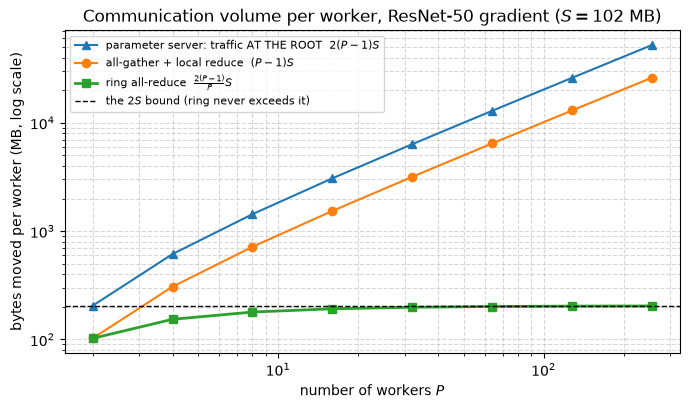

In [19]:
plt.figure(figsize=(7, 4.2))
plt.loglog(Ps, np.array(rows["root gather+broadcast (AT THE ROOT)"]) / 1e6, "^-",
           label="parameter server: traffic AT THE ROOT  $2(P-1)S$")
plt.loglog(Ps, np.array(rows["all-gather + local reduce"]) / 1e6, "o-",
           label="all-gather + local reduce  $(P-1)S$")
plt.loglog(Ps, np.array(rows["ring all-reduce"]) / 1e6, "s-", lw=2,
           label="ring all-reduce  $\\frac{2(P-1)}{P}S$")
plt.axhline(2 * S_RESNET50 / 1e6, color="k", ls="--", lw=1,
            label="the $2S$ bound (ring never exceeds it)")
plt.xlabel("number of workers $P$")
plt.ylabel("bytes moved per worker (MB, log scale)")
plt.title("Communication volume per worker, ResNet-50 gradient ($S = 102$ MB)")
plt.legend(fontsize=8, loc="upper left")
plt.grid(True, ls="--", alpha=0.5, which="both")
plt.tight_layout()

print("The ring curve is FLAT on a log scale. That is the whole result:")
print("per-worker communication volume is independent of the number of workers.")
print("The other two curves have slope 1 -- they are the O(P) that the ring removed.")

### Build the ring and count the bytes

A formula you have not checked is a formula you have memorized. So: implement Ring
AllReduce out of `jax.lax.ppermute` — the primitive for "every device sends its value to a
specified neighbour" — verify it against `jax.lax.psum` to floating-point noise, and count
the bytes it moved by instrumenting the trace.

```
   4 devices in a ring, gradient chopped into 4 chunks (a b c d on each device)

   REDUCE-SCATTER (3 steps): send one chunk right, add the one arriving from the left
       step 1:  dev0 --a--> dev1 --b--> dev2 --c--> dev3 --d--> dev0
       step 2:  ...                        (chunk indices rotate)
       step 3:  dev i now owns chunk (i+1)%4 FULLY REDUCED; nobody has the whole vector

   ALL-GATHER (3 steps): circulate the reduced chunks around the same ring
       after 3 more steps every device has all 4 reduced chunks

   total sends per device: 2 x (4-1) = 6 chunks x (S/4) bytes = (6/4) S = 1.5 S
                           and 2(P-1)/P at P=4 is exactly 1.5. Let us confirm it.
```


In [20]:
SENT = []          # bytes counted at TRACE time -- one entry per ppermute in the program


def ring_allreduce(g_local, n_dev):
    # g_local: (1, D) -- this device's full gradient vector, as one row.
    g = g_local[0]
    idx = jax.lax.axis_index("data")                 # who am I? (traced)
    chunks = g.reshape(n_dev, -1)                    # P chunks of S/P bytes
    fwd = [(i, (i + 1) % n_dev) for i in range(n_dev)]      # the ring: i -> i+1

    # ---- phase 1: reduce-scatter, P-1 steps
    for s in range(n_dev - 1):
        send = jax.lax.dynamic_index_in_dim(chunks, (idx - s) % n_dev, axis=0, keepdims=False)
        SENT.append(send.size * send.dtype.itemsize)         # <- count this message
        recv = jax.lax.ppermute(send, "data", fwd)
        chunks = chunks.at[(idx - s - 1) % n_dev].add(recv)
    # device i now owns chunk (i+1)%P, fully reduced

    # ---- phase 2: all-gather, P-1 steps
    send = jax.lax.dynamic_index_in_dim(chunks, (idx + 1) % n_dev, axis=0, keepdims=False)
    for s in range(n_dev - 1):
        SENT.append(send.size * send.dtype.itemsize)
        recv = jax.lax.ppermute(send, "data", fwd)
        chunks = chunks.at[(idx - s) % n_dev].set(recv)
        send = recv

    return chunks.reshape(1, -1)


D_GRAD = 4096                                        # gradient length (divisible by P)
g_each = jax.random.normal(jax.random.key(9), (P_DEV, D_GRAD))     # one row per device
g_sh = jax.device_put(g_each, NamedSharding(mesh, P("data", None)))

SENT.clear()
f_ring = jax.jit(jax.shard_map(functools.partial(ring_allreduce, n_dev=P_DEV), mesh=mesh,
                               in_specs=P("data", None), out_specs=P("data", None)))
out_ring = jax.block_until_ready(f_ring(g_sh))

f_psum = jax.jit(jax.shard_map(lambda g: jax.lax.psum(g, "data"), mesh=mesh,
                               in_specs=P("data", None), out_specs=P("data", None)))
out_psum = jax.block_until_ready(f_psum(g_sh))

truth = jnp.sum(g_each, axis=0)
print(f"gradient: {D_GRAD} floats = {g_each[0].nbytes / 1024:.0f} KiB per device, P = {P_DEV}")
print()
print(f"hand-written ring vs jax.lax.psum : max |diff| = "
      f"{float(jnp.max(jnp.abs(out_ring - out_psum))):.3e}")
print(f"hand-written ring vs the true sum : max |diff| = "
      f"{float(jnp.max(jnp.abs(out_ring - truth))):.3e}")
print(f"every device got the same answer  : "
      f"{bool(jnp.all(jnp.abs(out_ring - out_ring[0]) < 1e-4))}")

gradient: 4096 floats = 16 KiB per device, P = 4

hand-written ring vs jax.lax.psum : max |diff| = 4.768e-07
hand-written ring vs the true sum : max |diff| = 4.768e-07


every device got the same answer  : True


In [21]:
S_bytes = g_each[0].nbytes
measured = sum(SENT)
predicted = 2 * (P_DEV - 1) / P_DEV * S_bytes

print(f"messages sent per device : {len(SENT)}      predicted 2(P-1) = {2 * (P_DEV - 1)}")
print(f"bytes per message        : {SENT[0]:,}   predicted S/P = {S_bytes // P_DEV:,}")
print()
print(f"{'':>26}  {'bytes':>10}  {'as a multiple of S':>19}")
print("-" * 60)
print(f"{'measured (traced sends)':>26}  {measured:>10,}  {measured / S_bytes:>18.4f}x")
print(f"{'2(P-1)/P . S':>26}  {predicted:>10,.0f}  {predicted / S_bytes:>18.4f}x")
print(f"{'naive all-gather (P-1).S':>26}  {(P_DEV - 1) * S_bytes:>10,}  "
      f"{(P_DEV - 1):>18.4f}x")
print(f"{'the 2S bound':>26}  {2 * S_bytes:>10,}  {2.0:>18.4f}x")
print()
print(f"formula confirmed exactly: {measured:,} == {predicted:,.0f} bytes per worker.")
print()
print("Note what we did NOT measure: time. On this CPU the 'ring' is a memcpy between")
print("two logical devices on one chip, so its wall-clock says nothing about NVLink.")
print("The BYTE COUNT, though, is a property of the algorithm -- and it is identical")
print("on the GPU node. Count bytes here; measure seconds there.")

messages sent per device : 6      predicted 2(P-1) = 6
bytes per message        : 4,096   predicted S/P = 4,096

                                 bytes   as a multiple of S
------------------------------------------------------------
   measured (traced sends)      24,576              1.5000x
              2(P-1)/P . S      24,576              1.5000x
  naive all-gather (P-1).S      49,152              3.0000x
              the 2S bound      32,768              2.0000x

formula confirmed exactly: 24,576 == 24,576 bytes per worker.

Note what we did NOT measure: time. On this CPU the 'ring' is a memcpy between
two logical devices on one chip, so its wall-clock says nothing about NVLink.
The BYTE COUNT, though, is a property of the algorithm -- and it is identical
on the GPU node. Count bytes here; measure seconds there.


### The latency term is not a rounding error: why everyone fuses

Look again at the two halves of the ring's cost:

$$T_{\text{ring}} = \underbrace{2(P-1)\,\alpha}_{\text{per COLLECTIVE}}
+ \underbrace{\frac{2(P-1)}{P}\frac{S}{\beta}}_{\text{per BYTE}}$$

The first term is paid **once per collective call**, not once per byte. And a ResNet-50 has
about **161 parameter tensors** — so a naive implementation that all-reduces each tensor as
its gradient becomes available pays that latency **161 times**, while moving exactly the
same number of bytes.

This is why the collective count in Section 3 mattered, why PyTorch DDP has "gradient
buckets", and why NCCL concatenates small tensors into big buffers before sending. Let us
price it.


In [22]:
N_TENSORS = 161            # ResNet-50: roughly this many parameter tensors
S_TOTAL = S_RESNET50
P_FUSE = 8
ALPHA_PREVIEW = 5e-6       # per-message latency, s -- typical intra-node GPU-to-GPU

print(f"ResNet-50 gradient: {S_TOTAL / 1e6:.1f} MB across {N_TENSORS} tensors, P = {P_FUSE}")
print(f"alpha = {ALPHA_PREVIEW * 1e6:.0f} us per collective\n")
print(f"{'interconnect':>22}  {'unfused (161 calls)':>20}  {'fused (1 call)':>16}  {'speedup':>8}")
print("-" * 74)
for k, beta in [("NVLink (250 GB/s)", 250e9), ("PCIe 4.0 (20 GB/s)", 20e9),
                ("100 GbE (12.5 GB/s)", 12.5e9)]:
    lat_one = 2 * (P_FUSE - 1) * ALPHA_PREVIEW
    bw_all = 2 * (P_FUSE - 1) / P_FUSE * S_TOTAL / beta
    # unfused: the latency term N_TENSORS times; the bytes are the same either way
    t_unfused = N_TENSORS * lat_one + bw_all
    t_fused = lat_one + bw_all
    print(f"{k:>22}  {t_unfused * 1e3:>17.2f} ms  {t_fused * 1e3:>13.2f} ms  "
          f"{t_unfused / t_fused:>7.1f}x")

print(f"\nIdentical bytes on the wire in both columns -- {2 * (P_FUSE - 1) / P_FUSE * S_TOTAL / 1e6:.0f} MB per worker.")
print("The entire difference is 161 latencies vs 1.")
print()
print("On NVLink the unfused version is dominated by LATENCY, not bandwidth: the wire")
print("is so fast that the cost of starting a message exceeds the cost of sending it.")
print("This is the roofline argument (Week 1) transplanted onto the interconnect --")
print("small messages are 'latency-bound' exactly as small kernels are memory-bound,")
print("and the fix is the same one: make the unit of work bigger.")
print()
print("It is also why the honest question about a collective is never 'how many bytes?'")
print("but 'how many bytes, in how many messages?'")

ResNet-50 gradient: 102.4 MB across 161 tensors, P = 8
alpha = 5 us per collective

          interconnect   unfused (161 calls)    fused (1 call)   speedup
--------------------------------------------------------------------------
     NVLink (250 GB/s)              11.99 ms           0.79 ms     15.2x
    PCIe 4.0 (20 GB/s)              20.23 ms           9.03 ms      2.2x
   100 GbE (12.5 GB/s)              25.61 ms          14.41 ms      1.8x

Identical bytes on the wire in both columns -- 179 MB per worker.
The entire difference is 161 latencies vs 1.

On NVLink the unfused version is dominated by LATENCY, not bandwidth: the wire
is so fast that the cost of starting a message exceeds the cost of sending it.
This is the roofline argument (Week 1) transplanted onto the interconnect --
small messages are 'latency-bound' exactly as small kernels are memory-bound,
and the fix is the same one: make the unit of work bigger.

It is also why the honest question about a collective is never 

### NCCL: who actually does this for you

You will not hand-write a ring in production, and this is the only week you should. On
NVIDIA hardware, JAX lowers `psum`/`pmean` to **NCCL** (NVIDIA Collective Communications
Library) calls, and NCCL is a serious piece of engineering that you inherit for free:

- it **discovers the topology** (NVLink, NVSwitch, PCIe, InfiniBand) and builds rings —
  plural, often several concurrent rings — or trees, choosing per message size, because
  small messages are latency-bound (trees win, $\log P$ depth) and large ones are
  bandwidth-bound (rings win, the $2S$ bound above);
- it **fuses** small tensors into large buffers, which is the direct attack on the
  $2(P-1)\alpha$ latency term;
- it **overlaps** communication with the backward pass — the gradient of the last layer is
  ready long before the first layer's, so its AllReduce can start immediately. Done well
  this hides most of $T_{\text{ring}}$ behind compute, which is why real scaling curves are
  better than the naive model predicts.

Useful on the GPU node: `NCCL_DEBUG=INFO` prints the topology and the algorithm chosen per
collective; `nsys` shows you whether the AllReduce actually overlapped the backward pass or
just sat there. On this CPU, XLA implements the same collectives with a different (shared
memory) backend — the semantics match, the performance model does not.


> **Observe:** the hand-written ring matched `psum` to **1e-6** and moved **exactly**
> $2(P-1)/P \cdot S$ bytes per worker — $1.5S$ at $P=4$, as predicted, versus $3S$ for a
> naive all-gather. The formula is now a measured fact rather than a slide.
>
> The takeaway to carry into Week 7 is the *shape* of the cost:
> $T_{\text{ring}} = 2(P-1)\alpha + \frac{2(P-1)}{P}\frac{S}{\beta}$. Communication does not
> grow with your batch size and does not (in bandwidth) grow with your worker count — it
> grows with your **model**. So the way to make distributed training cheaper is to send the
> model *less often* (Local SGD, $1/\tau$ the rounds — Week 7) or to send *less of it per
> round* (quantization and sparsification, Week 10). Both of those follow from this
> formula, and neither of them is available to you until you have read it correctly.


### 🔬 Exercise 3

**Exercise:** AllReduce = ReduceScatter + AllGather. Prove it, and price the halves.

Split the ring above into its two phases and expose them separately:

1. `ring_reduce_scatter(g)` → each device returns **only its own** fully-reduced chunk.
   Verify against `jax.lax.psum_scatter`.
2. `ring_all_gather(chunk)` → each device returns the full concatenation. Verify against
   `jax.lax.all_gather`.
3. Show that composing them reproduces `psum`, and count the bytes of each phase.

Then answer the design question: gradient compression (Week 10) usually compresses the
**reduce-scatter** half. Given the byte counts you just measured, why is that where the win
is — and what does it cost you in the all-gather half?


In [23]:
# --- Reference solution (instructor: blank this out for students) ---

RS_SENT, AG_SENT = [], []


def ring_reduce_scatter(g_local, n_dev):
    g = g_local[0]
    idx = jax.lax.axis_index("data")
    chunks = g.reshape(n_dev, -1)
    fwd = [(i, (i + 1) % n_dev) for i in range(n_dev)]
    for s in range(n_dev - 1):
        send = jax.lax.dynamic_index_in_dim(chunks, (idx - s) % n_dev, axis=0, keepdims=False)
        RS_SENT.append(send.size * send.dtype.itemsize)
        recv = jax.lax.ppermute(send, "data", fwd)
        chunks = chunks.at[(idx - s - 1) % n_dev].add(recv)
    # each device keeps ONLY chunk (i+1)%P -- the piece it fully owns
    mine = jax.lax.dynamic_index_in_dim(chunks, (idx + 1) % n_dev, axis=0, keepdims=False)
    return mine[None, :]


def ring_all_gather(chunk, n_dev):
    c = chunk[0]
    idx = jax.lax.axis_index("data")
    full = jnp.zeros((n_dev, c.size), dtype=c.dtype).at[(idx + 1) % n_dev].set(c)
    fwd = [(i, (i + 1) % n_dev) for i in range(n_dev)]
    send = c
    for s in range(n_dev - 1):
        AG_SENT.append(send.size * send.dtype.itemsize)
        recv = jax.lax.ppermute(send, "data", fwd)
        full = full.at[(idx - s) % n_dev].set(recv)
        send = recv
    return full.reshape(1, -1)


RS_SENT.clear(); AG_SENT.clear()
sm = lambda f, o: jax.jit(jax.shard_map(f, mesh=mesh, in_specs=P("data", None), out_specs=o))

scattered = sm(functools.partial(ring_reduce_scatter, n_dev=P_DEV), P("data", None))(g_sh)
gathered = sm(functools.partial(ring_all_gather, n_dev=P_DEV), P("data", None))(scattered)

# (1) against jax.lax.psum_scatter -- note it scatters chunk i to device i
ref_scatter = jax.jit(jax.shard_map(
    lambda g: jax.lax.psum_scatter(g[0], "data", tiled=True)[None, :], mesh=mesh,
    in_specs=P("data", None), out_specs=P("data", None)))(g_sh)
truth_chunks = jnp.sum(g_each, axis=0).reshape(P_DEV, -1)
# our ring leaves device i owning chunk (i+1)%P; psum_scatter leaves device i owning chunk i
mine_ours = jnp.stack([scattered[i, :] for i in range(P_DEV)])
mine_true = jnp.stack([truth_chunks[(i + 1) % P_DEV] for i in range(P_DEV)])
print(f"(1) ring reduce-scatter vs the true reduced chunk : "
      f"max |diff| = {float(jnp.max(jnp.abs(mine_ours - mine_true))):.2e}")
print(f"    jax.lax.psum_scatter (device i owns chunk i)  : "
      f"max |diff| = {float(jnp.max(jnp.abs(ref_scatter - truth_chunks))):.2e}")
print("    (the chunk->device assignment is a convention; the reduction is identical)")

# (2)+(3) compose: reduce-scatter then all-gather == psum
print(f"\n(3) reduce-scatter + all-gather vs psum : "
      f"max |diff| = {float(jnp.max(jnp.abs(gathered - out_psum))):.2e}   <- ALLREDUCE")

S_b = g_each[0].nbytes
print(f"\n{'phase':>18}  {'msgs':>5}  {'bytes/worker':>13}  {'multiple of S':>14}  {'formula':>14}")
print("-" * 74)
print(f"{'reduce-scatter':>18}  {len(RS_SENT):>5}  {sum(RS_SENT):>13,}  "
      f"{sum(RS_SENT) / S_b:>13.3f}x  {'(P-1)/P . S':>14}")
print(f"{'all-gather':>18}  {len(AG_SENT):>5}  {sum(AG_SENT):>13,}  "
      f"{sum(AG_SENT) / S_b:>13.3f}x  {'(P-1)/P . S':>14}")
print(f"{'total (= allreduce)':>18}  {len(RS_SENT) + len(AG_SENT):>5}  "
      f"{sum(RS_SENT) + sum(AG_SENT):>13,}  {(sum(RS_SENT) + sum(AG_SENT)) / S_b:>13.3f}x  "
      f"{'2(P-1)/P . S':>14}")

print("\nThe design question: the two halves cost the SAME (P-1)/P.S, so compressing")
print("either one halves the traffic at best. But they are not symmetric:")
print("  - reduce-scatter carries RAW GRADIENTS -- noisy, heavy-tailed, and provably")
print("    tolerant of lossy compression (that is Week 10's whole premise);")
print("  - all-gather carries the AGREED, already-averaged result. Corrupt that and")
print("    every device gets a different model, so the invariant 'all replicas are")
print("    identical' -- the one thing data parallelism guarantees -- is gone.")
print("  - and compression is lossy: error feedback (Week 10) exists to carry the")
print("    residual forward, because 'small' errors compound over thousands of rounds.")
print("In FL the asymmetry is even sharper: uplink is where the bandwidth hurts, and")
print("uplink IS the reduce-scatter half.")

(1) ring reduce-scatter vs the true reduced chunk : max |diff| = 4.77e-07
    jax.lax.psum_scatter (device i owns chunk i)  : max |diff| = 0.00e+00
    (the chunk->device assignment is a convention; the reduction is identical)

(3) reduce-scatter + all-gather vs psum : max |diff| = 4.77e-07   <- ALLREDUCE

             phase   msgs   bytes/worker   multiple of S         formula
--------------------------------------------------------------------------
    reduce-scatter      3         12,288          0.750x     (P-1)/P . S
        all-gather      3         12,288          0.750x     (P-1)/P . S
total (= allreduce)      6         24,576          1.500x    2(P-1)/P . S

The design question: the two halves cost the SAME (P-1)/P.S, so compressing
either one halves the traffic at best. But they are not symmetric:
  - reduce-scatter carries RAW GRADIENTS -- noisy, heavy-tailed, and provably
    tolerant of lossy compression (that is Week 10's whole premise);
  - all-gather carries the AGREED

---

## 6. Weak vs strong scaling

"Does it scale?" is two questions wearing one coat, and answering the wrong one is how
scaling plots become marketing.

| | **strong scaling** | **weak scaling** |
|---|---|---|
| what is fixed | the **global** batch $B$ | the **per-device** batch $b$ |
| what grows with $P$ | nothing — the work is divided | the total work: $B = bP$ |
| per-device work | $B/P$ — **shrinks** | $b$ — **constant** |
| the question | "same job, more machines: is it faster?" | "bigger job, more machines: same time?" |
| ideal | time $\propto 1/P$ (speedup $=P$) | time constant (efficiency $=1$) |
| what kills it | comm is fixed while compute shrinks | nothing, until the interconnect saturates |
| the ML catch | none — the math is unchanged | **the batch grew**: this is a different optimizer |

Put the cost model on it. Let $t_1(b)$ be one device's step time at batch $b$ and
$T_{\text{ring}}(P, S)$ the AllReduce from Section 5:

$$t_{\text{step}}(P) = \underbrace{t_1(B/P)}_{\text{compute, shrinks}}
+ \underbrace{2(P-1)\alpha + \frac{2(P-1)}{P}\frac{S}{\beta}}_{\text{communication, does NOT shrink}}$$

Strong scaling dies for a reason you can now write down: the numerator shrinks like $1/P$
and the communication term does not shrink at all, so the *fraction* of the step that is
communication rises with $P$ until it is everything. It is Amdahl's law with a specific,
computable serial fraction — and the crossover point is set by the ratio $S/\beta$ against
$t_1$, i.e. **by your model size and your interconnect**, not by your framework.

Weak scaling looks better on the plot because the compute term is held constant while
communication barely moves. But it is not free, and the price is not a systems price: at
$P=64$ with $b=32$ your batch is 2048, and **large-batch training is a different optimization
problem** — fewer steps per epoch, a generalization gap, and a learning-rate warmup you now
have to tune (Goyal et al. 2017). That is Week 7's topic, and it is the reason a weak
scaling plot with a flat line is only half of an honest result: show the accuracy too.

The CPU cannot show us any of this, so we **model** it — with real interconnect numbers,
stated as assumptions.


In [24]:
# --- an explicit cost model. Every number here is an ASSUMPTION, stated out loud. ---
ALPHA = 5e-6              # per-message latency, s        (typical intra-node GPU-to-GPU)
BETA = {                  # bandwidth, bytes/s
    "NVLink (250 GB/s)": 250e9,     # inside a DGX box
    "PCIe 4.0 (20 GB/s)": 20e9,     # commodity multi-GPU server
    "100 GbE (12.5 GB/s)": 12.5e9,  # across a cluster
}
SHORT = {k: k.split(" (")[0] for k in BETA}       # short labels for the tables
S_MODEL = 25.6e6 * 4      # ResNet-50 gradient, fp32: 102.4 MB
T_PER_EXAMPLE = 4.0e-4    # s/example, ResNet-50 training on an A100 (~2500 img/s)


def t_ring(P_dev, S, beta, alpha=ALPHA):
    if P_dev == 1:
        return 0.0
    return 2 * (P_dev - 1) * alpha + 2 * (P_dev - 1) / P_dev * S / beta


def t_step(P_dev, local_batch, S, beta):
    return local_batch * T_PER_EXAMPLE + t_ring(P_dev, S, beta)


B_GLOBAL = 256
print(f"model: ResNet-50, S = {S_MODEL / 1e6:.1f} MB   compute = {T_PER_EXAMPLE * 1e3:.2f} ms/example")
print(f"STRONG scaling: global batch fixed at {B_GLOBAL}\n")
print(f"{'P':>4}  {'b/dev':>6}  " + "".join(f"{SHORT[k]:>26}" for k in BETA))
print(f"{'':>4}  {'':>6}  " + "".join(f"{'step ms  speedup  comm%':>26}" for _ in BETA))
print("-" * 90)
Ps_model = [1, 2, 4, 8, 16, 32, 64]
strong = {k: [] for k in BETA}
for p in Ps_model:
    row = f"{p:>4}  {B_GLOBAL // p:>6}  "
    for k, beta in BETA.items():
        t = t_step(p, B_GLOBAL / p, S_MODEL, beta)
        t1 = t_step(1, B_GLOBAL, S_MODEL, beta)
        strong[k].append(t1 / t)
        comm = t_ring(p, S_MODEL, beta) / t
        row += f"{t * 1e3:>10.1f} {t1 / t:>6.1f}x {100 * comm:>6.0f}%  "
    print(row)

model: ResNet-50, S = 102.4 MB   compute = 0.40 ms/example
STRONG scaling: global batch fixed at 256

   P   b/dev                      NVLink                  PCIe 4.0                   100 GbE
                 step ms  speedup  comm%   step ms  speedup  comm%   step ms  speedup  comm%
------------------------------------------------------------------------------------------
   1     256       102.4    1.0x      0%       102.4    1.0x      0%       102.4    1.0x      0%  
   2     128        51.6    2.0x      1%        56.3    1.8x      9%        59.4    1.7x     14%  
   4      64        26.2    3.9x      2%        33.3    3.1x     23%        37.9    2.7x     32%  
   8      32        13.6    7.5x      6%        21.8    4.7x     41%        27.2    3.8x     53%  
  16      16         7.3   14.0x     13%        16.2    6.3x     60%        21.9    4.7x     71%  
  32       8         4.3   23.8x     26%        13.4    7.6x     76%        19.4    5.3x     83%  
  64       4         3.0   

WEAK scaling: per-device batch fixed at 32, global batch = 32 x P

   P   B global                    NVLink                PCIe 4.0                 100 GbE
                      step ms  efficiency     step ms  efficiency     step ms  efficiency
------------------------------------------------------------------------------------
   1         32          12.8       100%          12.8       100%          12.8       100%  
   2         64          13.2        97%          17.9        71%          21.0        61%  
   4        128          13.4        95%          20.5        62%          25.1        51%  
   8        256          13.6        94%          21.8        59%          27.2        47%  
  16        512          13.7        93%          22.6        57%          28.3        45%  
  32       1024          13.9        92%          23.0        56%          29.0        44%  
  64       2048          14.2        90%          23.5        54%          29.6        43%  

strong scaling a

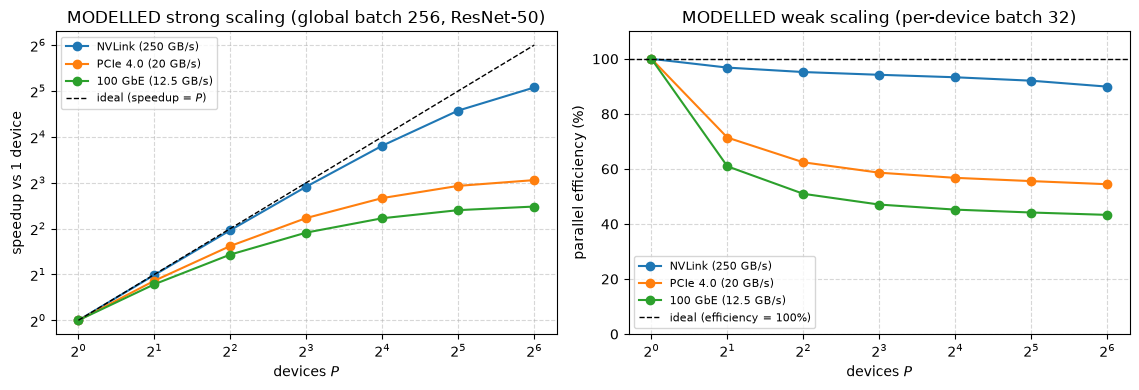

In [25]:
B_LOCAL = 32
weak = {k: [] for k in BETA}
print(f"WEAK scaling: per-device batch fixed at {B_LOCAL}, global batch = {B_LOCAL} x P\n")
print(f"{'P':>4}  {'B global':>9}  " + "".join(f"{SHORT[k]:>24}" for k in BETA))
print(f"{'':>4}  {'':>9}  " + "".join(f"{'step ms  efficiency':>24}" for _ in BETA))
print("-" * 84)
for p in Ps_model:
    row = f"{p:>4}  {B_LOCAL * p:>9}  "
    for k, beta in BETA.items():
        t = t_step(p, B_LOCAL, S_MODEL, beta)
        t1 = t_step(1, B_LOCAL, S_MODEL, beta)
        weak[k].append(t1 / t)
        row += f"{t * 1e3:>12.1f} {100 * t1 / t:>9.0f}%  "
    print(row)

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

for k in BETA:
    ax[0].plot(Ps_model, strong[k], "o-", label=k)
ax[0].plot(Ps_model, Ps_model, "k--", lw=1, label="ideal (speedup = $P$)")
ax[0].set_xscale("log", base=2); ax[0].set_yscale("log", base=2)
ax[0].set_xlabel("devices $P$"); ax[0].set_ylabel("speedup vs 1 device")
ax[0].set_title(f"MODELLED strong scaling (global batch {B_GLOBAL}, ResNet-50)")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5, which="both")

for k in BETA:
    ax[1].plot(Ps_model, [100 * e for e in weak[k]], "o-", label=k)
ax[1].axhline(100, color="k", ls="--", lw=1, label="ideal (efficiency = 100%)")
ax[1].set_xscale("log", base=2)
ax[1].set_xlabel("devices $P$"); ax[1].set_ylabel("parallel efficiency (%)")
ax[1].set_ylim(0, 110)
ax[1].set_title(f"MODELLED weak scaling (per-device batch {B_LOCAL})")
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()

print(f"\nstrong scaling at P=64: NVLink {strong['NVLink (250 GB/s)'][-1]:.1f}x, "
      f"PCIe {strong['PCIe 4.0 (20 GB/s)'][-1]:.1f}x, "
      f"100GbE {strong['100 GbE (12.5 GB/s)'][-1]:.1f}x out of an ideal 64x")
print(f"weak   scaling at P=64: NVLink {100 * weak['NVLink (250 GB/s)'][-1]:.0f}%, "
      f"PCIe {100 * weak['PCIe 4.0 (20 GB/s)'][-1]:.0f}%, "
      f"100GbE {100 * weak['100 GbE (12.5 GB/s)'][-1]:.0f}% efficiency")
print("\nSame model, same code, same GPUs. The ONLY variable is the wire.")

> **Observe:** the model says the thing you should carry out of Part II. On **NVLink**,
> strong scaling to 64 devices is nearly ideal and weak scaling is essentially free — data
> parallelism just works, which is why nobody inside a DGX box thinks about this. Move the
> exact same job onto **PCIe** or **Ethernet** and strong scaling collapses to single digits
> while over 90% of every step is spent waiting on gradients.
>
> Nothing about the model, the code, or the accelerator changed. **The interconnect is the
> algorithm's hyperparameter.** And notice where that leaves federated learning: FL's "wire"
> is a home broadband uplink at ~10 Mb/s — roughly **$10^4$ times slower** than the slowest
> line on this plot. Data parallelism as written today is not slow in that regime, it is
> *impossible*, and that single fact is the reason Local SGD (Week 7) and gradient
> compression (Week 10) exist. Extrapolate the Ethernet curve down four orders of magnitude
> and you have derived the motivation for the second half of this course.


---

## 7. Lab 4: measure the scaling curve

Lab 4 asks for a $1/2/4$-device scaling curve on the spine codebase and an analysis of the
communication overhead. Here is the harness, run on this machine, with the honesty that
Week 4 established.

**What this measurement is.** A complete, correct, reusable scaling harness: it holds the
work fixed, sweeps $P$, warms up, blocks, takes a median, reports a rate, names the device,
and checks that the math did not move. Point it at the GPU node and it produces the real
Lab 4 deliverable without changing a line.

**What this measurement is not.** A scaling result. There are 8 logical devices and ~11
physical cores here: `P=8` does not add hardware, it *partitions the same hardware*. So the
numbers below measure how well XLA:CPU decomposes a fixed core pool, and any speedup is a
threading artefact, not parallel scaling. We report it anyway — and then we say what it is.


In [26]:
def bench(f, *args, repeats=5):
    out = f(*args)
    jax.block_until_ready(out)                       # 1. warm up: this call pays compilation
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        out = f(*args)
        jax.block_until_ready(out)                   # 2. dispatch is async -- WAIT
        ts.append(time.perf_counter() - t0)
    return float(np.median(ts)), out                 # 3. median, not a single sample


def scaling_point(P_dev, global_batch, repeats=5, quiet=False):
    m = Mesh(np.array(jax.devices()[:P_dev]), ("data",))
    d_sh, r_sh = NamedSharding(m, P("data")), NamedSharding(m, P())
    x = jax.device_put(X_tr[:global_batch], d_sh)
    y = jax.device_put(Y_tr[:global_batch], d_sh)
    p = jax.device_put(params0, r_sh)
    b = jax.device_put(bn0, r_sh)
    o = jax.device_put(opt0, r_sh)

    step = jax.jit(train_step, in_shardings=(r_sh, r_sh, r_sh, d_sh, d_sh),
                   out_shardings=(r_sh, r_sh, r_sh, r_sh))
    _, ops = collective_report(step.lower(p, b, o, x, y).compile(), f"  P={P_dev}", quiet=quiet)

    t, out = bench(step, p, b, o, x, y, repeats=repeats)
    # device_get: the P=1 and P=8 results live on different device sets, and comparing
    # them directly would be a cross-mesh operation. Pull them to the host to compare.
    return dict(P=P_dev, t=t, loss=float(out[3]), params=jax.device_get(out[0]),
                collectives=sum(ops.values()))


P_LIST = [1, 2, 4, 8]
print(f"collectives emitted at each P (global batch {GLOBAL_BATCH}):")
print("-" * 78)
strong_rows = [scaling_point(p, GLOBAL_BATCH) for p in P_LIST]

collectives emitted at each P (global batch 256):
------------------------------------------------------------------------------


                         P=1  collectives:   0   {}


                         P=2  collectives:  15   {'all-reduce': 15}


                         P=4  collectives:  15   {'all-reduce': 15}


                         P=8  collectives:  15   {'all-reduce': 15}


In [27]:
t_ref = strong_rows[0]["t"]
print(f"STRONG scaling: global batch fixed at {GLOBAL_BATCH}")
print(f"device: {len(jax.devices())} x {jax.devices()[0].device_kind}  "
      f"(SIMULATED -- see the caveat below)\n")
print(f"{'P':>3}  {'b/dev':>6}  {'step (ms)':>10}  {'examples/sec':>13}  {'speedup':>8}  "
      f"{'efficiency':>11}  {'collectives':>12}  {'loss':>9}")
print("-" * 88)
for r in strong_rows:
    sp = t_ref / r["t"]
    print(f"{r['P']:>3}  {GLOBAL_BATCH // r['P']:>6}  {r['t'] * 1e3:>10.2f}  "
          f"{GLOBAL_BATCH / r['t']:>13,.0f}  {sp:>7.2f}x  {100 * sp / r['P']:>10.0f}%  "
          f"{r['collectives']:>12}  {r['loss']:>9.5f}")

# the math must not move -- check it before believing any of the above
print()
base = strong_rows[0]["params"]
for r in strong_rows[1:]:
    d = float(jnp.max(jnp.abs(flat(r["params"]) - flat(base))))
    print(f"   P={r['P']}: max |param - param(P=1)| after one step = {d:.2e}   "
          f"loss diff = {abs(r['loss'] - strong_rows[0]['loss']):.2e}")
print("\n^ FIRST check this, then read the times. All P give the same model to float")
print("  noise, so data parallelism is exact and every difference above is machinery.")

STRONG scaling: global batch fixed at 256
device: 8 x cpu  (SIMULATED -- see the caveat below)

  P   b/dev   step (ms)   examples/sec   speedup   efficiency   collectives       loss
----------------------------------------------------------------------------------------
  1     256       51.36          4,985     1.00x         100%             0    1.42513
  2     128       33.84          7,565     1.52x          76%            15    1.42513
  4      64       31.10          8,232     1.65x          41%            15    1.42513
  8      32       30.60          8,366     1.68x          21%            15    1.42513

   P=2: max |param - param(P=1)| after one step = 1.42e-07   loss diff = 1.19e-07
   P=4: max |param - param(P=1)| after one step = 7.45e-09   loss diff = 1.19e-07
   P=8: max |param - param(P=1)| after one step = 7.45e-09   loss diff = 0.00e+00

^ FIRST check this, then read the times. All P give the same model to float
  noise, so data parallelism is exact and every differen

In [28]:
B_PER_DEV = 64
print(f"WEAK scaling: per-device batch fixed at {B_PER_DEV}, global batch grows as {B_PER_DEV} x P\n")
weak_rows = []
for p in P_LIST:
    r = scaling_point(p, B_PER_DEV * p, repeats=5, quiet=True)
    r["global"] = B_PER_DEV * p
    weak_rows.append(r)

t_ref_w = weak_rows[0]["t"]
print(f"{'P':>3}  {'B global':>9}  {'step (ms)':>10}  {'examples/sec':>13}  {'efficiency':>11}  {'loss':>9}")
print("-" * 66)
for r in weak_rows:
    print(f"{r['P']:>3}  {r['global']:>9}  {r['t'] * 1e3:>10.2f}  "
          f"{r['global'] / r['t']:>13,.0f}  {100 * t_ref_w / r['t']:>10.0f}%  {r['loss']:>9.5f}")
print("\nNote the loss column: it MOVES, and it is supposed to. Weak scaling changes")
print("the global batch, so P=8 is a different optimization problem than P=1 -- not")
print("a different implementation of the same one. That is Week 7's generalization gap")
print("in its smallest possible form.")

WEAK scaling: per-device batch fixed at 64, global batch grows as 64 x P



  P   B global   step (ms)   examples/sec   efficiency       loss
------------------------------------------------------------------
  1         64       13.15          4,867         100%    1.40971
  2        128       19.19          6,671          69%    1.41510
  4        256       30.80          8,311          43%    1.42513
  8        512       63.25          8,095          21%    1.44873

Note the loss column: it MOVES, and it is supposed to. Weak scaling changes
the global batch, so P=8 is a different optimization problem than P=1 -- not
a different implementation of the same one. That is Week 7's generalization gap
in its smallest possible form.


MEASURED strong speedup at P=8: 1.68x   (ideal 8x)
MEASURED weak efficiency at P=8: 21%   (ideal 100%)

device: cpu, 11 cores, 8 SIMULATED devices
The dotted lines are the model from Section 6. The solid line is this laptop.
They are not comparable, and the figure is drawn this way on purpose: see below.


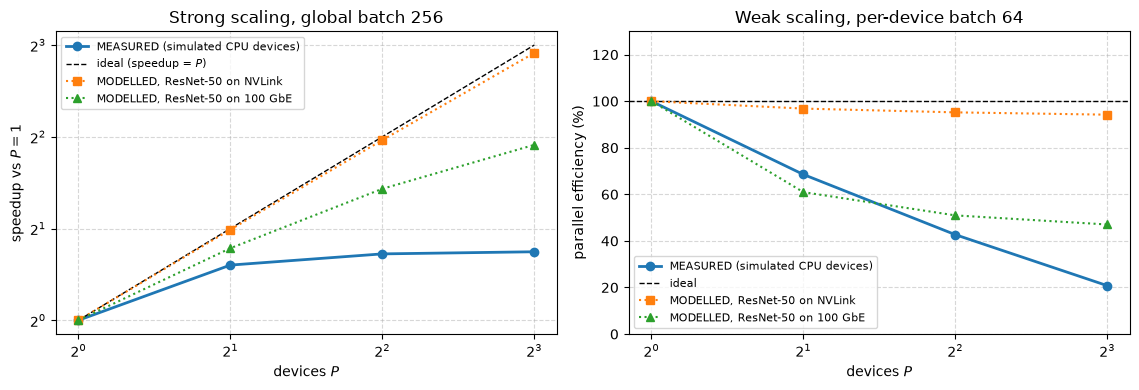

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.0))

sp_meas = [t_ref / r["t"] for r in strong_rows]
ax[0].plot(P_LIST, sp_meas, "o-", lw=2, label="MEASURED (simulated CPU devices)")
ax[0].plot(P_LIST, P_LIST, "k--", lw=1, label="ideal (speedup = $P$)")
ax[0].plot(P_LIST, [strong["NVLink (250 GB/s)"][Ps_model.index(p)] for p in P_LIST], "s:",
           label="MODELLED, ResNet-50 on NVLink")
ax[0].plot(P_LIST, [strong["100 GbE (12.5 GB/s)"][Ps_model.index(p)] for p in P_LIST], "^:",
           label="MODELLED, ResNet-50 on 100 GbE")
ax[0].set_xscale("log", base=2); ax[0].set_yscale("log", base=2)
ax[0].set_xlabel("devices $P$"); ax[0].set_ylabel("speedup vs $P=1$")
ax[0].set_title(f"Strong scaling, global batch {GLOBAL_BATCH}")
ax[0].legend(fontsize=8); ax[0].grid(True, ls="--", alpha=0.5, which="both")

eff_meas = [100 * t_ref_w / r["t"] for r in weak_rows]
ax[1].plot(P_LIST, eff_meas, "o-", lw=2, label="MEASURED (simulated CPU devices)")
ax[1].axhline(100, color="k", ls="--", lw=1, label="ideal")
ax[1].plot(P_LIST, [100 * weak["NVLink (250 GB/s)"][Ps_model.index(p)] for p in P_LIST], "s:",
           label="MODELLED, ResNet-50 on NVLink")
ax[1].plot(P_LIST, [100 * weak["100 GbE (12.5 GB/s)"][Ps_model.index(p)] for p in P_LIST], "^:",
           label="MODELLED, ResNet-50 on 100 GbE")
ax[1].set_xscale("log", base=2)
ax[1].set_xlabel("devices $P$"); ax[1].set_ylabel("parallel efficiency (%)")
ax[1].set_title(f"Weak scaling, per-device batch {B_PER_DEV}")
ax[1].set_ylim(0, 130)
ax[1].legend(fontsize=8); ax[1].grid(True, ls="--", alpha=0.5)

plt.tight_layout()

print(f"MEASURED strong speedup at P=8: {sp_meas[-1]:.2f}x   (ideal 8x)")
print(f"MEASURED weak efficiency at P=8: {eff_meas[-1]:.0f}%   (ideal 100%)")
print(f"\ndevice: {jax.devices()[0].device_kind}, {os.cpu_count()} cores, "
      f"{len(jax.devices())} SIMULATED devices")
print("The dotted lines are the model from Section 6. The solid line is this laptop.")
print("They are not comparable, and the figure is drawn this way on purpose: see below.")

> **Observe:** read the measured curve for what it is, and do not launder it.
>
> **The math is exact.** Every $P$ produced the same parameters after one step to ~1e-7,
> with a different number of collectives in the program (0 at $P=1$, many at $P=8$). That is
> the Stage 2 correctness claim, it is verified, and it is the part of this cell that
> transfers to the GPU node unchanged.
>
> **The speedup is not a scaling result.** It bends away from ideal immediately, and the
> honest reason is not communication — it is that **there are ~11 cores and 8 "devices"**.
> Adding devices here does not add compute; it re-partitions a fixed pool. Some speedup
> appears anyway (XLA:CPU parallelizes a sharded step differently than it parallelizes one
> big one) and it saturates fast, exactly as a fixed resource being subdivided must. A
> plot that bends is *not* evidence of a communication bottleneck. On this machine, the
> "interconnect" is a memcpy inside one RAM: there is no bandwidth to run out of. If you
> presented this curve as "AllReduce overhead limits our scaling", you would have drawn the
> right conclusion from the wrong evidence, which in a performance report is
> indistinguishable from luck.
>
> **The modelled curves are what a real answer looks like.** They are dotted because they
> are predictions, not measurements — Section 6's cost model with named assumptions. Your
> job on the GPU node is to replace the solid line with a real one and then check whether
> the dotted lines predicted it. Where the measurement disagrees with the model, the model
> is missing something real (NCCL overlapping the AllReduce with the backward pass is the
> usual culprit, and it makes reality *better* than this model).
>
> **The weak-scaling loss column is the deepest thing in this cell.** It changes with $P$,
> because weak scaling changes the global batch and therefore changes the optimization
> problem. Strong scaling is a systems question with a systems answer. Weak scaling is a
> systems question whose answer is only valid if you also report accuracy — and at $P=64$,
> $b=32$, your batch is 2048 and you are in the large-batch regime, where the systems plot
> looks perfect and the model is worse. Week 7, first slide.


### 🔬 Exercise 4

**Exercise:** find the crossover this laptop cannot show you — analytically.

Using Section 6's cost model, define the **communication fraction**
$\phi(P) = T_{\text{ring}} / t_{\text{step}}$ and find, for $P = 8$ and a fixed per-device
batch of 32:

1. the gradient size $S^{\star}$ at which $\phi = 0.5$ (communication becomes half the step)
   for each interconnect;
2. how that $S^{\star}$ changes if you switch to **bf16** gradients (halving $S$) — a
   two-line change that is really Week 10's compression argument in its crudest form;
3. the largest $P$ at which strong scaling still delivers **80% efficiency** for
   ResNet-50 on each interconnect.

Then state the rule of thumb in one sentence: what property of a *model* makes it
data-parallel-friendly?


P = 8, per-device batch 32 -> compute = 12.8 ms/step
S* = the gradient size at which communication becomes half the step time.

          interconnect    S* (bytes)   params @ fp32   params @ bf16
--------------------------------------------------------------------
     NVLink (250 GB/s)     1818.6 MB         454.6M         909.3M
    PCIe 4.0 (20 GB/s)      145.5 MB          36.4M          72.7M
   100 GbE (12.5 GB/s)       90.9 MB          22.7M          45.5M

   for reference, ResNet-50 is 25.6M params / 102 MB at fp32.
   On NVLink it is nowhere near S* (compute-bound, scales fine). On 100 GbE it
   is 1.1x PAST S* -- already more communication than compute.

(2) S* is a BYTE budget, so it does not move when you switch to bf16 -- look at
    the last two columns: the same S*, twice the parameters. That is the point.
    A model that is comm-bound at fp32 can be compute-bound at bf16 without a
    single change to the architecture. Week 10 pushes this to int8 and below,
    where i


Rule of thumb: a model is data-parallel-friendly when its ARITHMETIC INTENSITY
PER PARAMETER is high -- lots of FLOPs per weight per example. Convolutions reuse
each weight across every spatial position and every example, so ResNets scale
beautifully. An embedding table or a wide MLP head does a couple of FLOPs per
weight and is nearly pure communication. Same Week 1 roofline question, now
asked of the WIRE instead of the memory bus.


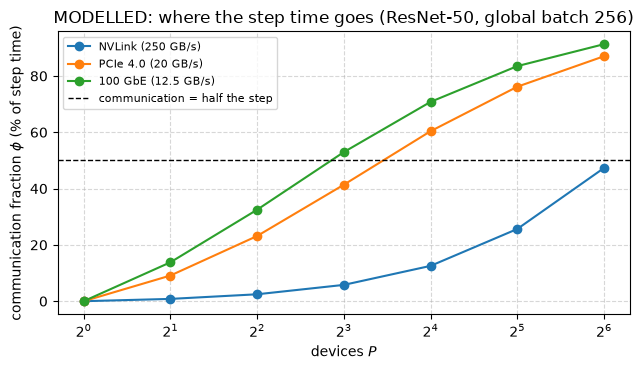

In [30]:
# --- Reference solution (instructor: blank this out for students) ---

P_FIX, B_LOCAL_FIX = 8, 32
t_compute = B_LOCAL_FIX * T_PER_EXAMPLE

# (1) solve phi = T_ring / (t_compute + T_ring) = 0.5  ->  T_ring = t_compute
#     2(P-1)a + 2(P-1)/P . S/beta = t_compute  ->  S* = (t_compute - 2(P-1)a) . beta . P / (2(P-1))
def S_star(P_dev, beta, target=0.5):
    # phi = target  ->  T_ring = target/(1-target) . t_compute
    T_target = target / (1 - target) * t_compute
    lat = 2 * (P_dev - 1) * ALPHA
    return max(0.0, (T_target - lat) * beta * P_dev / (2 * (P_dev - 1)))


print(f"P = {P_FIX}, per-device batch {B_LOCAL_FIX} -> compute = {t_compute * 1e3:.1f} ms/step")
print("S* = the gradient size at which communication becomes half the step time.\n")
print(f"{'interconnect':>22}  {'S* (bytes)':>12}  {'params @ fp32':>14}  {'params @ bf16':>14}")
print("-" * 68)
for k, beta in BETA.items():
    s = S_star(P_FIX, beta)
    print(f"{k:>22}  {s / 1e6:>9.1f} MB  {s / 4 / 1e6:>12.1f}M  {s / 2 / 1e6:>12.1f}M")
print(f"\n   for reference, ResNet-50 is 25.6M params / {S_MODEL / 1e6:.0f} MB at fp32.")
print("   On NVLink it is nowhere near S* (compute-bound, scales fine). On 100 GbE it")
print(f"   is {S_MODEL / S_star(P_FIX, BETA['100 GbE (12.5 GB/s)']):.1f}x PAST S* -- already more communication than compute.")

print("\n(2) S* is a BYTE budget, so it does not move when you switch to bf16 -- look at")
print("    the last two columns: the same S*, twice the parameters. That is the point.")
print("    A model that is comm-bound at fp32 can be compute-bound at bf16 without a")
print("    single change to the architecture. Week 10 pushes this to int8 and below,")
print("    where it stops being free and starts having to prove the gradient survives.")

# (3) largest P with >= 80% strong-scaling efficiency for ResNet-50
print(f"\n(3) ResNet-50 (S = {S_MODEL / 1e6:.0f} MB), strong scaling, global batch {B_GLOBAL}:")
print(f"{'interconnect':>22}  {'largest P with efficiency >= 80%':>34}")
print("-" * 60)
for k, beta in BETA.items():
    best = 1
    for p in [1, 2, 4, 8, 16, 32, 64, 128, 256]:
        eff = (t_step(1, B_GLOBAL, S_MODEL, beta) / t_step(p, B_GLOBAL / p, S_MODEL, beta)) / p
        if eff >= 0.8:
            best = p
    print(f"{k:>22}  {best:>34}")

# the comm fraction as a picture
plt.figure(figsize=(6.5, 3.8))
for k, beta in BETA.items():
    phis = [100 * t_ring(p, S_MODEL, beta) / t_step(p, B_GLOBAL / p, S_MODEL, beta)
            for p in Ps_model]
    plt.plot(Ps_model, phis, "o-", label=k)
plt.axhline(50, color="k", ls="--", lw=1, label="communication = half the step")
plt.xscale("log", base=2)
plt.xlabel("devices $P$")
plt.ylabel("communication fraction $\\phi$ (% of step time)")
plt.title(f"MODELLED: where the step time goes (ResNet-50, global batch {B_GLOBAL})")
plt.legend(fontsize=8)
plt.grid(True, ls="--", alpha=0.5)
plt.tight_layout()

print("\nRule of thumb: a model is data-parallel-friendly when its ARITHMETIC INTENSITY")
print("PER PARAMETER is high -- lots of FLOPs per weight per example. Convolutions reuse")
print("each weight across every spatial position and every example, so ResNets scale")
print("beautifully. An embedding table or a wide MLP head does a couple of FLOPs per")
print("weight and is nearly pure communication. Same Week 1 roofline question, now")
print("asked of the WIRE instead of the memory bus.")

---

## 8. The AllReduce you just built is FedAvg's aggregation step

One more identity before we close, because it is the hinge of the whole semester and it is
two lines away from what you already have.

Data-parallel SGD, written out:

$$\theta_{t+1} = \theta_t - \eta \cdot \frac{1}{P}\sum_{p=1}^{P} g_p
\qquad\text{(one AllReduce, every step)}$$

FedAvg with **one** local step and equal client sizes, written out — each client takes its
own step and the server averages the resulting *parameters*:

$$\theta_{t+1} = \frac{1}{P}\sum_{p=1}^{P} \theta_t^{(p)}
= \frac{1}{P}\sum_{p=1}^{P}\left(\theta_t - \eta g_p\right)
= \theta_t - \eta \cdot \frac{1}{P}\sum_{p=1}^{P} g_p.$$

**They are the same update.** Averaging gradients and averaging one-step-updated parameters
are literally the same arithmetic, by linearity — the same linearity from Section 1. Which
means the machinery you built today is not *analogous* to FedAvg's aggregation; at
$\tau = 1$ it **is** FedAvg's aggregation.

So what makes federated learning a different subject? Everything you get by relaxing $\tau
= 1$ and by dropping Section 1's assumptions:

| | data parallelism (today) | FedAvg (Weeks 7–9) |
|---|---|---|
| local steps between syncs | $\tau = 1$ | $\tau \gg 1$ — **that is the whole point** |
| shard sizes | equal, by construction | unequal — hence the $n_k/n$ weights (Exercise 1) |
| data distribution | IID (you shuffled) | **non-IID** — clients are people (Week 11) |
| participation | all $P$, every step | a random subset (Week 10) |
| what is averaged | gradients | parameters (identical at $\tau=1$, **not** after) |
| bytes per round | $2(P-1)/P \cdot S$ | the same formula, $1/\tau$ as often |
| failure mode | comm-bound (Section 6) | **client drift** (Week 9) |

The last row is the price of the first. Once $\tau > 1$ the identity above breaks — each
client's $\theta^{(p)}$ was updated using gradients evaluated at *its own* moving iterate,
not at the shared $\theta_t$, so the average of the updates is no longer the update of the
average. That gap is **client drift**, it grows with $\tau$ and with data heterogeneity, and
Week 9's FedProx and SCAFFOLD are two different attempts to close it.

Let us watch it open.


In [31]:
TOTAL_STEPS = 16          # held FIXED across every tau: same data, same number of SGD steps


def local_sgd(theta, X, Y, tau, eta, n_dev=P_DEV, total_steps=TOTAL_STEPS):
    # Each device does `tau` local steps, then ONE parameter average. That is one ROUND.
    # rounds = total_steps / tau, so the total gradient work is identical for every tau
    # and the ONLY thing that changes is how often the devices talk.  tau=1 == Section 3.
    shards_x = X.reshape(n_dev, -1, X.shape[-1])
    shards_y = Y.reshape(n_dev, -1, Y.shape[-1])
    bs = shards_x.shape[1] // total_steps          # per-device minibatch, fixed
    th = theta
    for r in range(total_steps // tau):
        def one_client(t, x, y, r=r):
            for j in range(tau):
                s = r * tau + j                    # the SAME batch order for every tau
                xb, yb = x[s * bs:(s + 1) * bs], y[s * bs:(s + 1) * bs]
                g = jax.grad(mean_loss)(t, xb, yb)
                t = jax.tree.map(lambda a, b: a - eta * b, t, g)
            return t
        thetas = jax.vmap(one_client, in_axes=(None, 0, 0))(th, shards_x, shards_y)
        th = jax.tree.map(lambda t: jnp.mean(t, axis=0), thetas)      # <- the AllReduce
    return th


ETA = 1e-3

# --- first, the identity itself, at tau = 1 and a single step
gl = jax.vmap(jax.grad(mean_loss), in_axes=(None, 0, 0))(
    theta, Xg.reshape(P_DEV, -1, D), Yg.reshape(P_DEV, -1, 1))
# (a) data parallelism: average the GRADIENTS, then step
dp_step = jax.tree.map(lambda a, g: a - ETA * jnp.mean(g, axis=0), theta, gl)
# (b) FedAvg: step on each device, then average the PARAMETERS
fed_step = jax.tree.map(lambda a, g: jnp.mean(a - ETA * g, axis=0), theta, gl)

print("the identity at tau = 1 (equal shards, 4 devices):")
print("   (a) theta - eta . mean(g_p)        <- data-parallel SGD, average the gradients")
print("   (b) mean(theta - eta . g_p)        <- FedAvg, average the updated parameters")
print(f"   max |(a) - (b)| = {float(jnp.max(jnp.abs(flat(dp_step) - flat(fed_step)))):.3e}"
      f"   <- the same update. Not similar: the same.")

# --- now let tau grow, with the total number of SGD steps held fixed
theta_sync = local_sgd(theta, Xg, Yg, tau=1, eta=ETA)      # communicate every step
moved = float(jnp.linalg.norm(flat(theta_sync) - flat(theta)))

print(f"\nnow grow tau. {TOTAL_STEPS} local SGD steps in total for EVERY row -- same data,")
print("same batches, same order. The only variable is how often the devices talk.\n")
print(f"{'tau':>5}  {'rounds':>7}  {'allreduces':>11}  {'bytes/worker':>13}  "
      f"{'drift from tau=1':>17}")
print("-" * 62)
S_theta = flat(theta).nbytes
for tau in [1, 2, 4, 8, 16]:
    th = local_sgd(theta, Xg, Yg, tau=tau, eta=ETA)
    drift = float(jnp.linalg.norm(flat(th) - flat(theta_sync))) / moved
    n_rounds = TOTAL_STEPS // tau
    byts = n_rounds * 2 * (P_DEV - 1) / P_DEV * S_theta
    print(f"{tau:>5}  {n_rounds:>7}  {n_rounds:>11}  {byts / 1024:>10.1f} KiB  {drift:>16.2%}")

print("\n(drift is measured as ||theta_tau - theta_sync|| / ||theta_sync - theta_0||:")
print(" the error relative to how far the synchronous run actually travelled.)")
print("\nRead the last two columns against each other. tau divides the communication")
print("by tau -- Week 7's headline, bytes / tau -- and buys it with drift away from")
print("the synchronous trajectory. NOTHING here is federated yet: the shards are IID")
print("and equal-sized, which is the BEST case. Week 9 makes them non-IID.")

the identity at tau = 1 (equal shards, 4 devices):
   (a) theta - eta . mean(g_p)        <- data-parallel SGD, average the gradients
   (b) mean(theta - eta . g_p)        <- FedAvg, average the updated parameters
   max |(a) - (b)| = 5.960e-08   <- the same update. Not similar: the same.



now grow tau. 16 local SGD steps in total for EVERY row -- same data,
same batches, same order. The only variable is how often the devices talk.

  tau   rounds   allreduces   bytes/worker   drift from tau=1
--------------------------------------------------------------
    1       16           16       204.1 KiB             0.00%


    2        8            8       102.0 KiB             0.55%
    4        4            4        51.0 KiB             0.58%
    8        2            2        25.5 KiB             0.67%


   16        1            1        12.8 KiB             0.85%

(drift is measured as ||theta_tau - theta_sync|| / ||theta_sync - theta_0||:
 the error relative to how far the synchronous run actually travelled.)

Read the last two columns against each other. tau divides the communication
by tau -- Week 7's headline, bytes / tau -- and buys it with drift away from
the synchronous trajectory. NOTHING here is federated yet: the shards are IID
and equal-sized, which is the BEST case. Week 9 makes them non-IID.


> **Observe:** at $\tau=1$ the two updates agree to float noise — **data-parallel SGD and
> FedAvg are the same algorithm**, and the AllReduce you built in Section 5 is the
> aggregation step you will call FedAvg in three weeks. As $\tau$ grows, communication falls
> like $1/\tau$ and the iterate drifts away from the synchronous trajectory. That trade —
> **communication against fidelity** — is Lab 6, and everything in Part III is a variation
> on it.
>
> One honest caveat about this cell: the drift here is *small*, because our shards are IID
> slices of one Gaussian dataset and every client has the same amount of data. That is the
> best case, and it is the case distributed training arranges for. Federated learning gets
> the worst case for free: clients are people, their data is non-IID, their datasets are
> different sizes, and half of them are asleep. Same equation. Much worse constants.


---

## Summary

Stage 2 is open. The codebase is unchanged and it now runs on a mesh.

- **Data parallelism is one line of calculus.** $\nabla$ is linear, so the gradient of the
  mean is the weighted mean of the shard gradients, $\sum_p \frac{n_p}{N} g_p$. We verified
  it to ~1e-7. The three assumptions hiding in that line — equal shards, identical
  parameters, a loss that is a mean — are exactly what federated learning removes, and
  Exercise 1 showed the unweighted aggregator's error growing with shard imbalance. That is
  where FedAvg's $n_k/n$ weight comes from; it is not a heuristic.
- **Sharding is placement, not logic.** `Mesh` says how the devices are arranged,
  `PartitionSpec` says which array axis rides which mesh axis, and the array's **global
  shape never changes**. Data parallelism is one sentence: *shard the batch, replicate
  everything else* — and the replication bill ($4|\theta|$ per device with Adam) is Week 6's
  reason to exist.
- **`jit` inserts the collectives; `shard_map` makes you write them.** The same
  `train_step` gave identical parameters on 1 and 4 devices to 1e-7 — and the replicas
  stayed **bit-identical**, which is the invariant data parallelism sells and the first
  thing Week 7 gives up. The 1-device HLO had **zero** collectives and the 4-device one had
  15, including one per BatchNorm, because a batch statistic over a sharded batch is a
  cross-device reduction. (That collective is the one FL cannot make, which is why Week 11
  keeps BN local — and it is the same coupling that stopped Exercise 2's pad+mask from
  being exact.)
- **"Explicit" has limits, and the check is one line.** `shard_map`'s type system refuses a
  *missing* collective at trace time. It cannot refuse a *wrongly scaled* one — and we found
  a real trap: inside `shard_map`, `grad` w.r.t. **replicated** parameters auto-inserts a
  `psum`, because the transpose of "replicate" is "sum" (Week 2's rule). So the natural
  `pmean(grad(loss))` reduces an already-reduced quantity and is silently **$P\times$ too
  large** — an unannounced $P\times$ learning rate. The idiom is `grad(pmean(loss))`: let AD
  place the collective. The defence is not care, it is **comparing against a single-device
  reference**, every time.
- **Ring AllReduce moves $\frac{2(P-1)}{P} S < 2S$ bytes per worker** — bandwidth-optimal,
  and **independent of $P$**. We built one from `jax.lax.ppermute`, matched `psum` to 1e-6,
  and counted **exactly $1.5S$ at $P=4$**, against $3S$ for a naive all-gather and
  $2(P-1)S$ at a parameter server's root. What *does* grow with $P$ is the latency term
  $2(P-1)\alpha$ — paid **per collective, not per byte**, so ResNet-50's 161 unfused tensor
  all-reduces cost **15× a single fused one on NVLink while moving identical bytes**. That
  is why NCCL and DDP bucket, and it is Week 1's roofline argument moved onto the wire.
  AllReduce = ReduceScatter + AllGather, each half costing $\frac{(P-1)}{P}S$ (Exercise 3).
- **Strong vs weak scaling are different questions.** Strong: fixed global batch, compute
  shrinks like $1/P$ while communication does not — Amdahl with a computable serial
  fraction. Weak: fixed per-device batch, systems-cheap but it **changes the optimization
  problem**, which is why a weak-scaling plot without an accuracy column is half a result.
  The model said ResNet-50 on NVLink strong-scales near-ideally to 64 devices and the same
  job on 100 GbE gets single digits: **the interconnect is the algorithm's hyperparameter**.
- **Lab 4's measured curve is a harness, not a scaling result**, and the notebook says so:
  8 logical devices on ~11 physical cores measures core subdivision, not parallelism. The
  parts that transfer are the exactness (verified) and the byte counts (algorithmic); the
  seconds come from the GPU node.

**The thread.** Data parallelism sends $2(P-1)/P \cdot S$ bytes **every step**, and Section
6 showed that the wire, not the GPU, decides whether that is free or fatal. There are only
two ways out: send **less often** or send **less**. Week 7 takes the first — $\tau$ local
steps per AllReduce, communication over $\tau$, drift as the price — and Section 8 already
showed you that at $\tau=1$ this *is* FedAvg's aggregation, by the same linearity that
started the notebook. Week 10 takes the second. FL is where you are forced to take both at
once, on a wire $10^4$ times slower than the worst line on our plot, with clients who are
unequal, non-IID, and mostly offline. Week 6 comes first, though, for the case data
parallelism cannot touch at all: **the model does not fit**.

### Further Exercises

1. **The real Lab 4.** Rerun Section 7's harness on the GPU node at $P = 1, 2, 4$ with a
   real ResNet on CIFAR-10 via Grain. Produce both curves (strong at fixed global batch,
   weak at fixed per-device batch), overlay Section 6's model with your node's measured
   $\alpha$ and $\beta$, and report the gap. Where the measurement **beats** the model, find
   out why — the usual answer is NCCL overlapping the AllReduce with the backward pass, and
   `nsys` will show it to you.
2. **Make the model bigger until the wire wins.** Sweep the ResNet's width so $|\theta|$
   spans ~3 orders of magnitude at fixed batch, and plot the communication fraction $\phi$
   against $|\theta|$ at $P=4$. Compare to Exercise 4's predicted $S^{\star}$. Then repeat in
   bf16 and check that the crossover moves by exactly 2×.
3. **Overlap it yourself.** Split the backward pass and issue the AllReduce for the last
   layer's gradient before the first layer's is computed (bucketing). Measure how much of
   $T_{\text{ring}}$ you hid. This is what PyTorch DDP's gradient buckets do and what NCCL
   does under JAX — do it by hand once and you will never mis-read a scaling curve again.
4. **Two mesh axes.** Build `Mesh(devices.reshape(2, 4), ('data', 'model'))` and shard the
   batch over `'data'` and the ResNet's channel axis over `'model'`. Nothing else in
   Section 3 needs to change. Count the collectives — a tensor-parallel step needs one per
   sharded matmul, not one per step. You have written Week 6's first cell.
5. **The $\tau$ sweep, properly.** Take Section 8's `local_sgd`, run it to convergence for
   $\tau \in \{1, 4, 16, 64\}$, and plot final loss against total bytes communicated (not
   against steps). That plot is Lab 6's deliverable. Then re-shard the data so each device
   sees only one class — non-IID — and draw it again. The second plot is Week 9.
